# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

**1. Що б змінилось (і що б зламалось), якби в BPE-тренер передали один суцільний рядок?**

`train_from_iterator` очікує *ітератор текстів*. Якщо передати звичайний `str`, Python при ітерації віддає **окремі символи**, тож кожен «текст» виявляється одним символом. Пари сусідніх символів тренер не бачить ніколи, і злиття (merges) між літерами не з'являються: словник вироджується в алфавіт (у клітинці 0.3.2: ≈ 315 записів замість запрошених 2000), а токенізатор стає практично посимвольним (фраза з 5 слів дає 28 токенів замість 13). Це тихий збій: помилки немає, просто токенізатор нічого не навчився. Якщо ж обгорнути рядок у список (`[one_string]`), результат збігається зі списком віршів (ті самі 2000 записів і ті самі 13 токенів). Різниця лише практична: корпус стає *однією* послідовністю, яку тренер не може розкласти між ядрами, а в пам'яті його треба тримати одним величезним блоком (на великих корпусах це ризик OOM). У моєму запуску на Colab час майже не відрізнявся (≈ 38 с для списку, ≈ 34 с для `[один рядок]`, ≈ 30 с для голого `str`, де тренер просто обробляє купу однобуквених «текстів»), тож виграшу в швидкості це не дає, а список окремих текстів природніше відображає структуру даних.

**2. З яких етапів складається токенізація?** (за [HF LLM Course, 6.8](https://huggingface.co/learn/llm-course/en/chapter6/8))

1. **Нормалізація (normalization):** очищення сирого тексту: Unicode-нормалізація (NFC/NFD), перетворення в нижній регістр, прибирання зайвих пробілів чи діакритики. Важливо не «перестаратись»: `BertNormalizer()` із налаштуваннями за замовчуванням (там `lowercase=True`, а разом із ним вмикається й `strip_accents`) перетворює українські «й» та «ї» на «и» та «і» (див. 2.1).
2. **Попередня токенізація (pre-tokenization):** розбиття тексту на «слова» (за пробілами, пунктуацією або регулярним виразом GPT-2 у ByteLevel). Це задає межі, всередині яких токени надалі можуть зливатися, але не перетинати їх.
3. **Модель токенізатора:** власне алгоритм (BPE, WordPiece, Unigram): розбиває кожне «слово» на підслова зі словника й перетворює їх на id.
4. **Постобробка (post-processing):** додає службові токени (`[CLS]`, `[SEP]`, `<eos>`…), формує `attention_mask`, `token_type_ids`, виконує обрізання (truncation) та доповнення (padding). Зворотний процес, з id у текст, виконує *декодер*.

**2 (друге). Що таке `"<unk>"` та `"<eos>"` у 2.1?**

`<unk>` (unknown) замінює символи чи слова, яких немає в словнику. У byte-level BPE з демо їх практично не буває, бо в початковому алфавіті є всі 256 байтів, тож будь-який текст можна розкласти на байти (у демо частка `<unk>` = 0%). `<eos>` (end of sequence) позначає кінець вірша/документа: його вставляють між творами, щоб модель вчилась, де текст закінчується. Передача обох у `special_tokens` резервує для них перші id (0 і 1) і гарантує, що тренер не зіллє їх із іншими символами.

**3. `VOCAB_SIZE` 16000 → 5000 на корпусі демо.** (код і вивід: клітинка 0.3.3, повний корпус із 17 918 віршів)

| | `VOCAB_SIZE` = 16000 | `VOCAB_SIZE` = 5000 |
|---|---|---|
| токенів на вірш (середнє) | ≈ 1027 | ≈ 1205 (+17%) |
| частка `<unk>` | 0.0000% | 0.0000% |
| символів на токен | ≈ 3.31 | ≈ 2.82 |
| символів у вікні `CONTEXT_LEN = 64` | ≈ 212 | ≈ 180 |

Менший словник не підвищує частку `<unk>`, тому що це *byte-level* BPE: словник завжди містить усі 256 байтів, а «менший словник» означає лише менше злиттів поверх них. Будь-який символ завжди можна розкласти на байти, тож невідомих токенів не з'являється. Але з меншою кількістю злиттів слова розпадаються на дрібніші частини, і закодований текст стає довшим (+17%). Через це за той самий `CONTEXT_LEN` модель бачить менше «справжнього» тексту (≈ 180 замість ≈ 212 символів), а на ту саму епоху корпусу потрібно більше кроків. Взамін менший словник дає меншу матрицю embedding і менший вихідний шар `lm_head`.

**4. Навіщо між віршами вставлено `<eos>` у 2.2?**

Корпус для mini-GPT це один довгий потік токенів, з якого беруться випадкові вікна. Без `<eos>` останній токен одного вірша впритул стикається з першим токеном наступного: модель бачить «один суцільний текст» і вчиться передбачати початок нового вірша з кінця попереднього, тобто вивчає хибні переходи між не пов'язаними текстами. Крім того, вона ніколи не бачить сигналу «тут текст закінчується», тому не вміє завершувати генерацію: текст на інференсі просто тече далі. З `<eos>` модель вчиться і ставити роздільник, і «скидати контекст» після нього.

**5. Формат і зміст `train_data` та `val_data` у 2.3.**

Це одновимірні тензори `torch.long` (int64) форми `(N,)`. Кожен елемент це **id токена** (індекс у словнику токенізатора), а не символ і не вектор: весь корпус, закодований токенізатором і склеєний в один потік, де вірші розділені `<eos>`. `train_data` це перші 90% потоку, `val_data` це решта 10%. Спліт послідовний (зріз), а не випадковий, щоб послідовність токенів лишалась цілою. Приклад з виводом `dtype`, `shape` і декодуванням перших id: клітинка 0.3.4.

**6. `assert`-тест відповідності частин батча.** Код: клітинка 0.3.4. Перевіряється, що (а) `x` і `y` мають форму `(BATCH_SIZE, CONTEXT_LEN)` та тип `long`; (б) `y` це `x`, зсунутий на один токен: `x[:, 1:] == y[:, :-1]`; (в) кожен рядок батча є суцільним зрізом корпусу з відомої позиції (`x = data[i:i+T]`, `y = data[i+1:i+T+1]`); (г) усі id лежать у межах словника.

**7. Чому `causal_mask` нижньотрикутна, і що було б без неї?**

У матриці уваги `scores[t, s]` рядок `t` це «запит» (позиція, яка вирішує, на що дивитись), стовпець `s` це «ключ» (на що дивляться). Нижньотрикутна маска дозволяє дивитись лише на `s ≤ t`, тобто на себе та **попередні** токени. Верхньотрикутна дозволила б бачити лише майбутнє, а це протилежно до задачі «передбач наступне слово». Без маски кожна позиція під час тренування бачить токен, який має передбачити (він лежить у позиції `t+1`), і модель вчиться його просто *копіювати*, а не передбачати. У клітинці 0.3.5 я навчив дві крихітні моделі: після 600 ітерацій з маскою loss закономірно лишається високим (≈ 6.0), а без маски падає майже до нуля (train ≈ 0.27, val ≈ 0.25), і це хибне досягнення: під час генерації майбутніх токенів ще не існує, тож «навичка підглядання» не працює, і текст вироджується в повтори на зразок «давандеван…» (див. вивід 0.3.5). Тобто без маски модель нічого не вчиться про мову, а метрика val_loss теж обманює, бо валідаційні вікна «підглядають» так само.

**8. Чекпоінт з найкращим `val_loss` проти останнього.**

Збігаються. У всіх чотирьох варіантів `best_iter` = 7999, тобто найкращий за `val_loss` чекпоінт і останній це один і той самий (у прогоні з `EVAL_INTERVAL = 50` теж). Причина: за 8000 ітерацій `val_loss` ще не перестав спадати (у `minigpt_v1` між ітераціями 7000 і 7999 він упав ще з 5.415 до 5.334), а ознак перенавчання (val росте, поки train падає) немає: розрив між train і val складає лише ≈ 0.43 (4.91 проти 5.33). Модель за весь час бачила корпус приблизно 4 рази (8000 · 64 · 64 ≈ 32.8 млн токенів проти 8.3 млн у train). Така сама картина й у демо: найкращий чекпоінт це ітерація 7999 (val_loss = 5.639). Різниця між «найкращим» і «останнім» з'явилась би лише при довшому тренуванні, коли val почне рости. Тоді чекпоінт з найменшим `val_loss` справді варто було б зберігати окремо. Поки що це радше свідчить, що моделі **недонавчені**, ніж перенавчені.

**10. `EVAL_INTERVAL` 250 → 50.**

Накладні витрати на оцінювання (клітинка 3.6, та сама базова конфігурація). `estimate_loss` усереднює loss по 50 батчах train і 50 батчах val (100 прямих проходів), і це коштує ≈ 1.4 с на T4.

| `EVAL_INTERVAL` | точок на кривій | час на `estimate_loss` | частка часу | повний час |
|---|---|---|---|---|
| 250 | 33 | ≈ 45 с | 13% | 5.9 хв |
| 50 | 161 | ≈ 223 с | 42% | 8.8 хв (+49%) |

Екстраполяція за цим виміром: інтервал 10 коштував би ≈ 18 хв самих оцінювань (втричі більше за тренування), інтервал 1 близько 3 годин. Тобто частішати швидко стає дорожче за саме навчання. Що дає частіша оцінка: крива густіша (161 точка замість 33), але **шумніша**, бо кожна точка усереднюється лише по 50 випадкових батчах: іноді val «стрибає» вгору (5.641 → 5.651 між ітераціями 4800 і 5000), а загальна форма кривої та висновок («val падає до кінця») лишаються тими самими. Кінцеві значення трохи відрізняються (val 5.304 проти 5.334) не через сам інтервал, а тому що оцінювання бере батчі з того самого генератора випадкових чисел і зсуває послідовність батчів під час тренування. Практично: 250 це розумний компроміс, частіше оцінювати має сенс лише для ранньої зупинки чи діагностики, і тоді краще зменшити `EVAL_ITERS`.

**11. Що робить `temperature` з логітами перед `softmax`?** (числовий приклад: клітинка 0.3.6)

Логіти `z_i` ділять на температуру `T` перед softmax: `p_i = exp(z_i / T) / Σ_j exp(z_j / T)`. При `T < 1` різниці між логітами *збільшуються*, розподіл гострішає (при `T → 0` це `argmax`, повністю детермінований вибір найімовірнішого токена, що й дає майже однакові, «безпечні» тексти). При `T > 1` різниці *згладжуються*, розподіл вирівнюється. Коли `T → ∞`, всі `z_i / T → 0`, `exp(0) = 1`, тож `p_i → 1/V`: рівномірний розподіл по всьому словнику (у Qwen ≈ 150 тис. токенів). Усе, що модель знає про мову, стирається, і наступний токен обирається майже навмання, звідси «випадковий» текст. У демо при `T = 1.4` текст ще лишається зв'язним лише тому, що поруч стоїть `top_p = 0.8`, який відрізає «хвіст» найнеймовірніших токенів (проте слова вже дивні: «заспокивально притиснувши до себе одязь»).

**12. За що відповідає `top_p`?**

`top_p` це *nucleus sampling*: токени сортуються за ймовірністю, береться найменший набір найімовірніших токенів, сумарна ймовірність яких ≥ `p`, решта відкидається, а ймовірності цього «ядра» перенормовуються. Далі токен вибирається семплуванням лише з нього. На відміну від `top_k` (завжди рівно `k` кандидатів), розмір ядра *адаптивний*: коли модель впевнена, у ядрі 1–2 токени, а коли сумнівається, воно ширше. Малий `top_p` (0.1) майже збігається з жадібним вибором, великий (≈ 1.0) нічого не відсікає.

**13. `enable_thinking=False` → `True` у 4.2.**

Результати (клітинка 0.3.7, `Qwen3-4B`, `temperature = 0.8`, `top_p = 0.6`, один seed):

| режим | токенів | час | що отримали |
|---|---|---|---|
| `thinking=False`, ліміт 300 | 168 | 14 с | одразу продовження оповідання українською (мова місцями коряво) |
| `thinking=True`, ліміт 300 | 300 | 20 с | лише початок блоку `<think>` англійською, **відповіді немає**: весь бюджет токенів пішов на «роздуми» |
| `thinking=True`, ліміт 1500 | 903 | 61 с | довгі міркування, генерація завершилась сама (903 < 1500), тож блок роздумів закінчився й відповідь після нього була |

Що змінилось: (1) з `enable_thinking=True` модель спершу пише ланцюжок міркувань у `<think>…</think>`, і він теж витрачає `max_new_tokens`; при малому ліміті користувач узагалі не побачить відповіді. (2) Ціна: ≈ 5× більше токенів і ≈ 4× більше часу (903 токени / 61 с проти 168 / 14 с). (3) Роздуми йшли англійською, хоча запит українською, і не гарантують точності: у них модель сама «виправила» Житомир на Хмельницький, що хибно, тож довший текст не означає кращий. (4) Для творчого продовження тексту міркування мало що додають, а от для задач із логікою чи арифметикою такий режим зазвичай доречніший. Висновок: `thinking` варто вмикати свідомо, із великим `max_new_tokens`, коли потрібна точність, і вимикати для швидкої чи креативної генерації.


### 0.3. Налаштування і код до відповідей

#### 0.3.0. Середовище

In [3]:
# 0.3.0. Налаштування середовища
import os, sys, subprocess, importlib.util

SMOKE = False   # True = швидкий «димовий» запуск на мініатюрних розмірах (лише для перевірки коду). Фінальний прогін: False

def pip_install(*pkgs):
    cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:                                   # у «керованих» системах повторюємо з прапорцем
        r = subprocess.run(cmd + ["--break-system-packages"], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"pip install {pkgs} не вдався:\n" + (r.stdout + r.stderr)[-2000:])

# transformers ставимо ДО першого імпорту і тієї самої версії, що й у шаблоні розділу 4
pip_install("transformers[sentencepiece]==5.18.0")
for mod, pkg in [("datasets", "datasets"), ("tokenizers", "tokenizers"), ("evaluate", "evaluate"),
                 ("gradio", "gradio"), ("tensorboard", "tensorboard"),
                 ("accelerate", "accelerate"), ("sklearn", "scikit-learn"), ("seaborn", "seaborn")]:
    if importlib.util.find_spec(mod) is None:
        pip_install(pkg)

os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")

'true'

In [4]:
import math, time, gc, json, random, shutil, zipfile, re, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import transformers
print("transformers", transformers.__version__, "| torch", torch.__version__)

IN_COLAB = "google.colab" in sys.modules
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device, "| Colab:", IN_COLAB, "| SMOKE:", SMOKE)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
elif not SMOKE:
    print("УВАГА: GPU не знайдено, повне тренування mini-GPT на CPU займе години. У Colab: Середовище виконання → T4 GPU.")

# Усі артефакти пишемо у відносні папки поруч із ноутбуком (працює і в Colab, і локально)
RUNS_DIR, MODELS_DIR = "runs", "models"
for d in (RUNS_DIR, MODELS_DIR):                 # чистий старт, щоб повторний запуск не дублював логи
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)

results_rows = []                                # сюди збираються рядки для results.csv (розділи 3 і 5)

def cleanup(hf_cache: bool = False):
    # звільняємо RAM/VRAM (і, лише в SMOKE-режимі, дисковий кеш моделей Hugging Face)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if hf_cache:
        shutil.rmtree(os.path.expanduser("~/.cache/huggingface/hub"), ignore_errors=True)

transformers 5.18.0 | torch 2.11.0+cu130
Використовуємо: cuda | Colab: True | SMOKE: False
GPU: Tesla T4


#### 0.3.1. Модель

Спільні класи mini-GPT (ті самі, що й у демо 3.3–3.6, тільки Q, K, V усіх голів рахуються одним матмулом, а маску можна вимкнути прапорцем `causal`: це знадобиться для питання 7). Кількість параметрів збігається з демо: **4 912 000** для конфігурації з демо.

In [5]:
class CausalSelfAttention(nn.Module):
    """Multi-head self-attention «вручну»: Q, K, V, маска, softmax. Без nn.MultiheadAttention."""
    def __init__(self, embed_dim, n_heads, context_len, dropout, causal=True):
        super().__init__()
        assert embed_dim % n_heads == 0
        self.n_heads, self.head_dim, self.causal = n_heads, embed_dim // n_heads, causal
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim, bias=False)   # Q, K, V для всіх голів одним матмулом
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.attn_dropout, self.resid_dropout = nn.Dropout(dropout), nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)
        q, k, v = [t.view(B, T, self.n_heads, self.head_dim).transpose(1, 2) for t in (q, k, v)]   # (B, H, T, d)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)                                 # (B, H, T, T)
        if self.causal:                                   # токен t не бачить токенів після себе
            scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.attn_dropout(F.softmax(scores, dim=-1))
        out = (weights @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(embed_dim, 4 * embed_dim), nn.ReLU(),
                                 nn.Linear(4 * embed_dim, embed_dim), nn.Dropout(dropout))
    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout, causal=True):
        super().__init__()
        self.attention = CausalSelfAttention(embed_dim, n_heads, context_len, dropout, causal)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1, self.norm2 = nn.LayerNorm(embed_dim), nn.LayerNorm(embed_dim)
    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.feed_forward(self.norm2(x))


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout, causal=True):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embed_dim, n_heads, context_len, dropout, causal)
                                      for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.final_norm(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)], dim=1)
        return idx


_m = MiniGPT(vocab_size=16000, embed_dim=128, n_heads=4, n_layers=4, context_len=64, dropout=0.1)
print("Параметрів у конфігурації з демо:", f"{sum(p.numel() for p in _m.parameters()):,}")
del _m

Параметрів у конфігурації з демо: 4,912,000


#### 0.3.2. Питання 1: список текстів проти одного рядка

In [6]:
# 0.3.2. Питання 1: список текстів проти одного рядка
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

POEMS_ID = "RudyiVT/ukrainian-poems"      # корпус із демо
poems_all = load_dataset(POEMS_ID, split="train").to_pandas()["context_poem"].dropna().tolist()
if SMOKE:
    poems_all = poems_all[:2000]
print("Віршів:", len(poems_all), "| символів:", sum(map(len, poems_all)))

def train_bpe(iterator, vocab_size):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"])
    tok.train_from_iterator(iterator, trainer=trainer)
    return tok

subset = poems_all[:3000]
one_string = "\n\n".join(subset)
test_phrase = "Реве та стогне Дніпр широкий"
rows = []
for name, iterator in [("список віршів", subset), ("[один рядок] (список з 1 елемента)", [one_string]), ("один рядок (str як є)", one_string)]:
    t0 = time.time()
    tok = train_bpe(iterator, 2000)
    rows.append({"що передали в тренер": name, "розмір словника": tok.get_vocab_size(),
                 "токенів у фразі": len(tok.encode(test_phrase).ids), "час, с": round(time.time() - t0, 1)})
display(pd.DataFrame(rows))
print("Приклад розбиття для «str як є»:", tok.encode(test_phrase).tokens[:8])

README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

Віршів: 17918 | символів: 60850362


,що передали в тренер,розмір словника,токенів у фразі,"час, с"
0,список віршів,2000,13,38.0
1,[один рядок] (список з 1 елемента),2000,13,34.2
2,один рядок (str як є),315,28,30.1


Приклад розбиття для «str як є»: ['Ðł', 'Ðµ', 'Ð²', 'Ðµ', 'Ġ', 'ÑĤ', 'Ð°', 'Ġ']


#### 0.3.3. Питання 3: `VOCAB_SIZE` 16000 → 5000 на корпусі демо

In [7]:
# 0.3.3. Питання 3: VOCAB_SIZE 16000 -> 5000 на корпусі демо (рахуємо пачками, щоб не вичерпати пам'ять)
def corpus_stats(tok, texts, batch=1000):
    n_tok = n_unk = n_chars = 0
    unk_id = tok.token_to_id("<unk>")
    for i in range(0, len(texts), batch):
        chunk = texts[i:i + batch]
        for enc in tok.encode_batch(chunk):
            n_tok += len(enc.ids); n_unk += enc.ids.count(unk_id)
        n_chars += sum(map(len, chunk))
    return n_tok, n_unk, n_chars

rows = []
vocab_list = [1500, 600] if SMOKE else [16000, 5000]
for V in vocab_list:
    tok_v = train_bpe(poems_all, V)
    n_tok, n_unk, n_chars = corpus_stats(tok_v, poems_all)
    rows.append({"VOCAB_SIZE": V, "токенів на вірш": round(n_tok / len(poems_all), 1),
                 "частка <unk>": f"{n_unk / n_tok:.4%}", "символів на токен": round(n_chars / n_tok, 2),
                 "символів у вікні 64 токенів": round(64 * n_chars / n_tok)})
    if V == vocab_list[-1]:
        tok_small = tok_v              # менший словник знадобиться нижче (0.3.4, 0.3.5)
    del tok_v; gc.collect()
display(pd.DataFrame(rows))

,VOCAB_SIZE,токенів на вірш,частка <unk>,символів на токен,символів у вікні 64 токенів
0,16000,1027.1,0.0000%,3.31,212
1,5000,1205.4,0.0000%,2.82,180


#### 0.3.4. Питання 5 і 6: формат `train_data` та `assert`-тест батча

In [8]:
# 0.3.4. Питання 5 і 6: формат train_data/val_data та assert-тест батча
ENC_BATCH = 1000
EOS_ID = tok_small.token_to_id("<eos>")
chunks = []
for i in range(0, len(poems_all), ENC_BATCH):
    for enc in tok_small.encode_batch(poems_all[i:i + ENC_BATCH]):
        chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
demo_data = torch.from_numpy(np.concatenate(chunks).astype(np.int64))
del chunks
split = int(len(demo_data) * 0.9)
demo_train, demo_val = demo_data[:split], demo_data[split:]

print("train_data:", demo_train.dtype, tuple(demo_train.shape), "| val_data:", demo_val.dtype, tuple(demo_val.shape))
print("перші 12 елементів train_data:", demo_train[:12].tolist())
print("це токени:", [tok_small.id_to_token(i) for i in demo_train[:6].tolist()])
print("декодовано:", repr(tok_small.decode(demo_train[:25].tolist())))

# --- Питання 6: assert-тест відповідності частин випадкового батча ---
CTX_T, BS_T = 64, 32

def get_batch_demo(source, ctx, bs, return_idx=False):
    ix = torch.randint(len(source) - ctx - 1, (bs,))
    x = torch.stack([source[i:i + ctx] for i in ix])
    y = torch.stack([source[i + 1:i + ctx + 1] for i in ix])
    return (x, y, ix) if return_idx else (x, y)

xb, yb, ix = get_batch_demo(demo_train, CTX_T, BS_T, return_idx=True)
assert xb.shape == yb.shape == (BS_T, CTX_T), "неправильна форма батча"
assert xb.dtype == yb.dtype == torch.long, "ids мають бути int64"
assert (xb[:, 1:] == yb[:, :-1]).all(), "y має бути x, зсунутим на один токен"
for r, i in enumerate(ix.tolist()):
    assert torch.equal(xb[r], demo_train[i:i + CTX_T]), f"рядок {r}: x не є зрізом корпусу"
    assert torch.equal(yb[r], demo_train[i + 1:i + CTX_T + 1]), f"рядок {r}: y не є зрізом корпусу"
assert 0 <= int(xb.min()) and int(xb.max()) < tok_small.get_vocab_size(), "id поза словником"
print("assert-тест батча: ОК")

train_data: torch.int64 (19454696,) | val_data: torch.int64 (2161633,)
перші 12 елементів train_data: [544, 4974, 183, 567, 211, 217, 1933, 2642, 339, 1041, 1114, 2322]
це токени: ['Ð£', 'ĠÐ³Ð¾ÑģÑĤÐ¸', 'Ð½', 'Ð½ÑĸÐ¹', 'ĠÐ±', 'Ð°Ð²']
декодовано: 'У гостинній бавилися розмовою три добре знайомі особи.\n\nОбі панночки торо'
assert-тест батча: ОК


#### 0.3.5. Питання 7: що буде без `causal_mask`

In [9]:
# 0.3.5. Питання 7: що буде без causal mask (крихітні моделі, кілька хвилин навіть на CPU)
tiny_ctx, tiny_bs, tiny_iters = 32, 32, (120 if SMOKE else 600)

def tiny_batch(src):
    ix = torch.randint(len(src) - tiny_ctx - 1, (tiny_bs,))
    return (torch.stack([src[i:i + tiny_ctx] for i in ix]), torch.stack([src[i + 1:i + tiny_ctx + 1] for i in ix]))

@torch.no_grad()
def tiny_eval(m):
    m.eval(); out = {}
    for k, s in (("train", demo_train), ("val", demo_val)):
        out[k] = round(float(np.mean([m(*tiny_batch(s))[1].item() for _ in range(20)])), 3)
    m.train(); return out

prompt_ids = torch.tensor([tok_small.encode("Реве та стогне").ids])
for causal in (True, False):
    set_seed()
    m = MiniGPT(tok_small.get_vocab_size(), 64, 4, 2, tiny_ctx, 0.0, causal=causal)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
    for it in range(tiny_iters):
        xb, yb = tiny_batch(demo_train); _, loss = m(xb, yb)
        opt.zero_grad(); loss.backward(); opt.step()
    torch.manual_seed(0)
    gen = tok_small.decode(m.generate(prompt_ids, 25, temperature=0.8, top_k=40)[0].tolist())
    print(f"causal_mask={causal!s:5s} | після {tiny_iters} ітерацій: {tiny_eval(m)}")
    print("   генерація:", repr(gen))

causal_mask=True  | після 600 ітерацій: {'train': 6.03, 'val': 6.033}
   генерація: "Реве та стогне ще, а в нього й посе, і я в п'язати. Дарну, то?\n\n"
causal_mask=False | після 600 ітерацій: {'train': 0.265, 'val': 0.252}
   генерація: 'Реве та стогненетю моріствае боганд нар давандевнеилась іще здригне недандевандеванднеандев'


#### 0.3.6. Питання 11: що робить температура

In [10]:
# 0.3.6. Питання 11: температура на прикладі логітів
logits = torch.tensor([4.0, 3.0, 2.0, 1.0, 0.0, -1.0])
rows = []
for T in [0.2, 0.5, 1.0, 1.4, 3.0, 10.0, 1000.0]:
    p = F.softmax(logits / T, dim=-1)
    rows.append({"T": T, **{f"p{i + 1}": round(float(v), 3) for i, v in enumerate(p)},
                 "макс. p": round(float(p.max()), 3), "ентропія, біт": round(float(-(p * p.log2()).sum()), 2)})
display(pd.DataFrame(rows))
print("Для 6 токенів рівномірний розподіл дає p = 1/6 ≈ 0.167 і ентропію log2(6) ≈ 2.58 біт.")

,T,p1,p2,p3,p4,p5,p6,макс. p,"ентропія, біт"
0,0.2,0.993,0.007,0.000,0.000,0.000,0.000,0.993,0.06
1,0.5,0.865,0.117,0.016,0.002,0.000,0.000,0.865,0.66
2,1.0,0.634,0.233,0.086,0.032,0.012,0.004,0.634,1.48
3,1.4,0.518,0.253,0.124,0.061,0.030,0.015,0.518,1.85
4,3.0,0.328,0.235,0.168,0.121,0.086,0.062,0.328,2.37
5,10.0,0.211,0.191,0.173,0.156,0.141,0.128,0.211,2.56
6,1000.0,0.167,0.167,0.167,0.167,0.166,0.166,0.167,2.58


Для 6 токенів рівномірний розподіл дає p = 1/6 ≈ 0.167 і ентропію log2(6) ≈ 2.58 біт.


#### 0.3.7. Питання 13: `enable_thinking`

In [11]:
# 0.3.7. Питання 13: enable_thinking False vs True (ті самі налаштування, що й у демо 4.2)
from transformers import AutoModelForCausalLM, AutoTokenizer

QWEN_ID = "Qwen/Qwen3-0.6B" if SMOKE else "Qwen/Qwen3-4B"     # у демо: Qwen3-4B
qwen_tok = AutoTokenizer.from_pretrained(QWEN_ID)
qwen = AutoModelForCausalLM.from_pretrained(QWEN_ID, torch_dtype="auto").to(device).eval()
print("Модель:", QWEN_ID, "| параметрів, млн:", round(sum(p.numel() for p in qwen.parameters()) / 1e6))

def qwen_generate(prompt, temperature, top_p, thinking, max_new_tokens=300):
    messages = [{"role": "user", "content": prompt}]
    text = qwen_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=thinking)
    inputs = qwen_tok([text], return_tensors="pt").to(device)
    out = qwen.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature, top_p=top_p)
    return qwen_tok.decode(out[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)

PLAYGROUND_PROMPT = ("Продовж речення: Якось уночі студент Житомирської політехніки прокинувся "
                     "від дивного шуму. Він підвівся з ліжка")
q13_outputs = {}
for thinking, budget in [(False, 300), (True, 300), (True, 1500)]:
    set_seed()
    t0 = time.time()
    txt = qwen_generate(PLAYGROUND_PROMPT, 0.8, 0.6, thinking, budget)
    q13_outputs[(thinking, budget)] = txt
    n_tok = len(qwen_tok(txt).input_ids)
    print(f"=== enable_thinking={thinking}, max_new_tokens={budget}: {n_tok} токенів, {time.time() - t0:.0f} с ===")
    print(txt[:1800] + (" […]" if len(txt) > 1800 else ""))
    print()
del qwen, qwen_tok
cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель: Qwen/Qwen3-4B | параметрів, млн: 4022
=== enable_thinking=False, max_new_tokens=300: 168 токенів, 14 с ===
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, зіштовхнувся об шафу і відразу ж почув, що в кімнаті щось відбувається. Забіглий вітер звідти звуковий, але не звичайний — це здавалось, навіть у відкритому вікні, як звук, що йде з іншої сторони.

=== enable_thinking=True, max_new_tokens=300: 300 токенів, 20 с ===
<think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." So, first, I need to make sure I understand the original sentence correctly. It's in Ukrainian, so I should be careful with the grammar and vocabulary.

The sentence starts with "Якось уночі..." which means "One night..." Then the student from the Kharkiv Polytechnic (Wait, no, it's Житомирської, which is Khmelnytskyi, not Kharkiv. So the student is from Khmelnyt

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### 1.1. Обраний датасет

**[`wikimedia/wikipedia`](https://huggingface.co/datasets/wikimedia/wikipedia), конфіг `20231101.uk`**: очищений текст статей української Вікіпедії. Жанр енциклопедичний, нейтральний «публіцистично-науковий» регістр із термінологією, датами, іменами та географічними назвами. Це зовсім інша мова, ніж віршована лексика демо (рими, архаїзми, звертання, коротші рядки).

Датасет величезний, тому беру **перші 12 000 статей через `streaming=True`**, залишаю статті від 1 500 символів і обрізаю кожну до ≈ 6 000 символів (за межею речення). Разом це кілька десятків мільйонів символів: достатньо, щоб токенізатори й mini-GPT побачили закономірності, і не так багато, щоб не поміститись у пам'ять. Оскільки це `IterableDataset`, спершу матеріалізую вибірку в список, а потім у `DataFrame` (`.to_pandas()` і `len()` у streaming-датасету немає).

In [12]:
# 1.1. Завантаження: українська Вікіпедія (wikimedia/wikipedia, конфіг 20231101.uk), перші статті через streaming
from datasets import load_dataset

N_ARTICLES = 300 if SMOKE else 12000
MIN_CHARS, MAX_CHARS = 1500, 6000      # відкидаємо стаби; довгі статті обрізаємо (щоб кілька гігантів не домінували)

stream = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
rows = list(stream.take(N_ARTICLES))           # IterableDataset -> список -> DataFrame (як радить умова)
wiki_df = pd.DataFrame(rows)
print("Колонки:", wiki_df.columns.tolist(), "| завантажено статей:", len(wiki_df))

def trim_to_sentence(text, limit=MAX_CHARS):
    if len(text) <= limit:
        return text
    cut = text[:limit]
    last = max(cut.rfind(". "), cut.rfind(".\n"))
    return cut[:last + 1] if last > 0.7 * limit else cut

wiki_df = wiki_df[wiki_df["text"].str.len() >= MIN_CHARS].copy()
wiki_df["text"] = wiki_df["text"].map(trim_to_sentence)
texts = wiki_df["text"].tolist()                 # список окремих статей (саме його отримують тренери токенізаторів)
print("Статей після фільтра довжини:", len(texts))

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Колонки: ['id', 'url', 'title', 'text'] | завантажено статей: 12000
Статей після фільтра довжини: 7972


### 1.2. Статистика корпусу

In [13]:
# 1.2. Статистика корпусу
from collections import Counter

corpus_text = "\n\n".join(texts)
words = re.findall(r"[а-щьюяєіїґ'ʼ-]+", corpus_text.lower())
freq = Counter(words)
print(f"Статей: {len(texts):,} | символів: {len(corpus_text):,} | слів: {len(words):,} | унікальних слів: {len(freq):,}")
print("Середня довжина статті, символів:", round(np.mean([len(t) for t in texts])))
print("Найчастіші слова:", freq.most_common(12))
print("\nПерші 500 символів:\n", corpus_text[:500])

Статей: 7,972 | символів: 34,356,729 | слів: 4,230,453 | унікальних слів: 305,150
Середня довжина статті, символів: 4308
Найчастіші слова: [('у', 86548), ('в', 86410), ('і', 71056), ('на', 68891), ('з', 58882), ('та', 54683), ('до', 43809), ('року', 24999), ('що', 24699), ('за', 23838), ('від', 17287), ('а', 16238)]

Перші 500 символів:
 Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

### 2.0. Розминка: `train_new_from_iterator` (HF 6.2)

In [14]:
# 2.0. Розминка (HF 6.2): train_new_from_iterator на основі архітектури готового токенізатора
from transformers import AutoTokenizer

def batch_iter(items, bs=500):
    for i in range(0, len(items), bs):
        yield items[i:i + bs]

WARM_TRAIN = texts[: (200 if SMOKE else 1500)]
WARM_VOCAB = 1500 if SMOKE else 8000
sample_text = "\n".join(texts[-60:])[:150_000]        # ЗРАЗОК ДЛЯ ПОРІВНЯНЬ: статті з кінця списку, у тренуванні не брали участі

qwen_base_tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
t0 = time.time()
warm_tok = qwen_base_tok.train_new_from_iterator(batch_iter(WARM_TRAIN), vocab_size=WARM_VOCAB)
print(f"Донавчено за {time.time() - t0:.0f} с")

n_base = len(qwen_base_tok(sample_text).input_ids)
n_new = len(warm_tok(sample_text).input_ids)
print(f"Словник: {len(qwen_base_tok):,} (Qwen) -> {len(warm_tok):,} (новий)")
print(f"Токенів на зразку з {len(sample_text):,} символів: Qwen = {n_base:,}  |  новий = {n_new:,}")
for w in ["Україна", "електромагнітний"]:
    print(f"  {w!r}: Qwen {qwen_base_tok.tokenize(w)}  |  новий {warm_tok.tokenize(w)}")
del qwen_base_tok, warm_tok
cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Донавчено за 7 с
Словник: 151,665 (Qwen) -> 8,008 (новий)
Токенів на зразку з 150,000 символів: Qwen = 79,411  |  новий = 50,402
  'Україна': Qwen ['Ð£', 'ÐºÑĢÐ°', 'ÑĹ', 'Ð½Ð°']  |  новий ['Ð£ÐºÑĢÐ°ÑĹÐ½Ð°']
  'електромагнітний': Qwen ['ÐµÐ»', 'ÐµÐºÑĤ', 'ÑĢÐ¾Ð¼', 'Ð°Ð³', 'Ð½', 'Ñĸ', 'ÑĤ', 'Ð½Ð¸Ð¹']  |  новий ['ÐµÐ»ÐµÐºÑĤ', 'ÑĢÐ¾Ð¼', 'Ð°Ð³', 'Ð½ÑĸÑĤ', 'Ð½Ð¸Ð¹']


### 2.1–2.3. Алгоритми BPE, WordPiece, Unigram (HF 6.5–6.7) на власному тексті

Спершу попередження для української мови: `BertNormalizer()` із налаштуваннями за замовчуванням (`lowercase=True` вмикає й `strip_accents`) ламає літери «й» та «ї». З `lowercase=False` цього не відбувається, але `strip_accents=True` повертає проблему.

In [15]:
# 2.1. Підводний камінь для української: BertNormalizer() за замовчуванням «з'їдає» діакритику (й -> и, ї -> і)
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers, processors

word = "Їжак йде крізь чагарник, а ґава кричить"
print("BertNormalizer() (за замовчуванням, lowercase=True): ", normalizers.BertNormalizer().normalize_str(word))
print("BertNormalizer(lowercase=False)                   : ", normalizers.BertNormalizer(lowercase=False).normalize_str(word))
print("BertNormalizer(lowercase=False, strip_accents=True): ", normalizers.BertNormalizer(lowercase=False, strip_accents=True).normalize_str(word))
print("NFC (залишаємо українські літери)                 : ", normalizers.NFC().normalize_str(word))

BertNormalizer() (за замовчуванням, lowercase=True):  іжак иде крізь чагарник, а ґава кричить
BertNormalizer(lowercase=False)                   :  Їжак йде крізь чагарник, а ґава кричить
BertNormalizer(lowercase=False, strip_accents=True):  Іжак иде крізь чагарник, а ґава кричить
NFC (залишаємо українські літери)                 :  Їжак йде крізь чагарник, а ґава кричить


Для всіх трьох алгоритмів беру однакову нормалізацію (**NFC**) і однаковий `vocab_size = 500`. Крім BPE з `ByteLevel` (як у демо) треную ще BPE над символами: так BPE порівнюється з Unigram за однакових умов (однаковий pre-tokenizer).

In [16]:
# 2.2. Три алгоритми (+ контрольний char-level BPE) на ОДНОМУ тексті, з однаковим vocab_size
V = 500
UNK = "[UNK]"
tok_train_texts = texts[: (100 if SMOKE else 300)]
norm = normalizers.NFC()

def build_bpe_byte():                              # як у демо: ByteLevel BPE
    t = Tokenizer(models.BPE(unk_token=UNK)); t.normalizer = norm
    t.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False); t.decoder = decoders.ByteLevel()
    tr = trainers.BpeTrainer(vocab_size=V, special_tokens=[UNK], initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    t.train_from_iterator(tok_train_texts, tr); return t

def build_bpe_char():                              # BPE над символами (Metaspace, як у Unigram)
    t = Tokenizer(models.BPE(unk_token=UNK)); t.normalizer = norm
    t.pre_tokenizer = pre_tokenizers.Metaspace(); t.decoder = decoders.Metaspace()
    t.train_from_iterator(tok_train_texts, trainers.BpeTrainer(vocab_size=V, special_tokens=[UNK])); return t

def build_wordpiece():
    t = Tokenizer(models.WordPiece(unk_token=UNK)); t.normalizer = norm
    t.pre_tokenizer = pre_tokenizers.BertPreTokenizer(); t.decoder = decoders.WordPiece(prefix="##")
    t.train_from_iterator(tok_train_texts, trainers.WordPieceTrainer(vocab_size=V, special_tokens=[UNK])); return t

def build_unigram():
    t = Tokenizer(models.Unigram()); t.normalizer = norm
    t.pre_tokenizer = pre_tokenizers.Metaspace(); t.decoder = decoders.Metaspace()
    t.train_from_iterator(tok_train_texts, trainers.UnigramTrainer(vocab_size=V, special_tokens=[UNK], unk_token=UNK)); return t

tokenizers_cmp = {"BPE (byte-level)": build_bpe_byte(), "BPE (char-level)": build_bpe_char(),
                  "WordPiece": build_wordpiece(), "Unigram": build_unigram()}
print({k: v.get_vocab_size() for k, v in tokenizers_cmp.items()})

{'BPE (byte-level)': 500, 'BPE (char-level)': 500, 'WordPiece': 500, 'Unigram': 500}


In [17]:
# 2.3. Етапи на прикладі: що робить pre-tokenizer і що «вивчили» алгоритми
phrase = "Київ — столиця України."
for name, t in tokenizers_cmp.items():
    print(f"{name:17s} pre-tokenize: {[p for p, _ in t.pre_tokenizer.pre_tokenize_str(phrase)][:6]}")

bpe_char = json.loads(tokenizers_cmp["BPE (char-level)"].to_str())["model"]
print("\nBPE: перші злиття (merges):", bpe_char["merges"][:10])
wp_vocab = json.loads(tokenizers_cmp["WordPiece"].to_str())["model"]["vocab"]
print("WordPiece: приклади словника:", [k for k in list(wp_vocab)[100:106]], "...", [k for k in wp_vocab if k.startswith("##")][20:26])
uni_vocab = json.loads(tokenizers_cmp["Unigram"].to_str())["model"]["vocab"]
print("Unigram: цілі слова зі найкращими оцінками:", [(k, round(s, 1)) for k, s in uni_vocab if len(k) > 4][:8])

BPE (byte-level)  pre-tokenize: ['ÐļÐ¸ÑĹÐ²', 'ĠâĢĶ', 'ĠÑģÑĤÐ¾Ð»Ð¸ÑĨÑı', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸', '.']
BPE (char-level)  pre-tokenize: ['▁Київ', '▁—', '▁столиця', '▁України.']
WordPiece         pre-tokenize: ['Київ', '—', 'столиця', 'України', '.']
Unigram           pre-tokenize: ['▁Київ', '▁—', '▁столиця', '▁України.']

BPE: перші злиття (merges): [['е', 'р'], ['а', 'н'], ['▁', 'п'], ['ь', 'к'], ['с', 'т'], ['р', 'о'], ['н', 'а'], ['н', 'я'], ['с', 'ьк'], ['▁', 'в']]
WordPiece: приклади словника: ['»', '¾', '×', 'Ø', 'á', 'ã'] ... ['##з', '##х', '##с', '##ч', '##s', '##c']
Unigram: цілі слова зі найкращими оцінками: [('[UNK]', 0.0), ('ський', -6.3), ('▁американськ', -6.4), ('▁актор', -6.6), ('▁український', -6.6), ('▁липня', -6.9), ('▁січня', -7.0), ('▁березня', -7.0)]


### 2.4. Порівняння

In [18]:
# 2.4. Таблиця порівняння (зразок: статті, яких не було в тренуванні)
probe_words = [("та", "частотне"), ("України", "частотне"), ("електромагнітний", "рідкісне"), ("термодинамічний", "рідкісне")]
print("Частоти слів у корпусі:", {w: freq.get(w.lower(), 0) for w, _ in probe_words})

rows, word_rows = [], []
for name, t in tokenizers_cmp.items():
    enc = t.encode(sample_text)
    unk_share = sum(1 for x in enc.tokens if x == UNK) / len(enc.ids)
    rows.append({"токенізатор": name, "розмір словника": t.get_vocab_size(), "токенів на зразку": len(enc.ids),
                 "символів на токен": round(len(sample_text) / len(enc.ids), 2), "частка [UNK]": f"{unk_share:.2%}"})
    word_rows.append({"токенізатор": name, **{f"{w} ({kind})": len(t.encode(w).ids) for w, kind in probe_words}})
display(pd.DataFrame(rows))
print("Кількість токенів на окремих словах:")
display(pd.DataFrame(word_rows))
print("Як саме розбиваються слова:")
for w, _ in probe_words[1:3]:
    for name, t in tokenizers_cmp.items():
        print(f"  {w:18s} {name:17s} {t.encode(w).tokens}")

Частоти слів у корпусі: {'та': 54683, 'України': 10722, 'електромагнітний': 1, 'термодинамічний': 0}


,токенізатор,розмір словника,токенів на зразку,символів на токен,частка [UNK]
0,BPE (byte-level),500,94055,1.59,0.00%
1,BPE (char-level),500,89185,1.68,0.02%
2,WordPiece,500,98965,1.52,0.01%
3,Unigram,500,92107,1.63,0.00%


Кількість токенів на окремих словах:


,токенізатор,та (частотне),України (частотне),електромагнітний (рідкісне),термодинамічний (рідкісне)
0,BPE (byte-level),2,4,10,8
1,BPE (char-level),1,3,11,8
2,WordPiece,1,3,12,11
3,Unigram,1,1,11,9


Як саме розбиваються слова:
  України            BPE (byte-level)  ['Ð', '£', 'ÐºÑĢÐ°ÑĹ', 'Ð½Ð¸']
  України            BPE (char-level)  ['▁У', 'краї', 'ни']
  України            WordPiece         ['У', '##краї', '##ни']
  України            Unigram           ['▁України']
  електромагнітний   BPE (byte-level)  ['ÐµÐ»', 'Ðµ', 'ÐºÑĤ', 'ÑĢ', 'Ð¾Ð¼', 'Ð°', 'Ð³', 'Ð½Ñĸ', 'ÑĤ', 'Ð½Ð¸Ð¹']
  електромагнітний   BPE (char-level)  ['▁', 'е', 'ле', 'кт', 'ро', 'м', 'а', 'г', 'ні', 'т', 'ний']
  електромагнітний   WordPiece         ['е', '##л', '##е', '##кт', '##р', '##ом', '##а', '##г', '##ні', '##т', '##ни', '##й']
  електромагнітний   Unigram           ['▁', 'е', 'ле', 'к', 'т', 'ро', 'ма', 'г', 'ні', 'т', 'ний']


**Висновок до порівняння токенізаторів** (словник 500 для всіх; зразок із 150 тис. символів, яких не було в тренуванні):

- Найкоротші послідовності дав **char-level BPE** (89 185 токенів, 1.68 символа/токен), далі **Unigram** (92 107; 1.63), **byte-level BPE** (94 055; 1.59) і найгірший **WordPiece** (98 965; 1.52). Проте різниця між першим і останнім лише ≈ 10%: при словнику з 500 слотів жоден алгоритм не вміщує багато цілих слів.
- **Byte-level BPE** найбільше «марнує» слоти: кожна кирилична літера це два байти, тож частина з 500 місць іде на байтові фрагменти (токени виду `Ð£`), і навіть «та» розпадається на 2 токени. Натомість він гарантує нуль `[UNK]`.
- Лише **Unigram** тримає частотне слово цілим: «України» це 1 токен (`▁України`), тоді як BPE і WordPiece розбивають його на 3 («У» + «краї» + «ни»). Для рідкісних слів («електромагнітний», «термодинамічний») усі алгоритми дають 8–12 токенів, тобто майже посимвольне розбиття.
- **WordPiece** виявився найгіршим: відщеплює першу літеру окремо («У», «##краї», «##ни») і витрачає слоти на «##»-продовження.
- `[UNK]` майже немає: 0.00% у byte-level BPE та Unigram, 0.01–0.02% у char-level BPE та WordPiece (рідкісні символи не потрапили в алфавіт із 500 слотів).
- Розминка 2.0: токенізатор Qwen (151 665 токенів у словнику) дає на тому ж зразку 79 411 токенів, а донавчений на нашому корпусі (8 008) лише 50 402 (≈ на 37% менше), і «Україна» стає одним токеном. Тобто словник, підібраний під мову, важить більше за сам алгоритм. У розділі 3 це видно ще раз: на всій Вікіпедії BPE на 16000 і на 5000 слотів дає 3.75 і 3.01 символа на токен проти ≈ 1.6 при 500.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [19]:
# 3.1. Корпус і токенізація: BPE на нашій Вікіпедії (для кожного VOCAB_SIZE свій токенізатор і своє кодування)
VOCAB_A, VOCAB_B = (1500, 800) if SMOKE else (16000, 5000)
ENC_BATCH_SIZE = 1000

def train_bpe_tokenizer(corpus_list, vocab_size):
    return train_bpe(corpus_list, vocab_size)                 # той самий ByteLevel BPE, що й у демо (0.3.2)

def encode_corpus(tok, corpus_list):
    eos_id = tok.token_to_id("<eos>")
    chunks = []
    for i in range(0, len(corpus_list), ENC_BATCH_SIZE):      # пачками, як у демо 2.2
        for enc in tok.encode_batch(corpus_list[i:i + ENC_BATCH_SIZE]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))   # <eos> між статтями
    return torch.from_numpy(np.concatenate(chunks).astype(np.int64))

corpora = {}
for V_ in (VOCAB_A, VOCAB_B):
    tok_ = train_bpe_tokenizer(texts, V_)
    data_ = encode_corpus(tok_, texts)
    unk_ = (data_ == tok_.token_to_id("<unk>")).float().mean().item()
    split_ = int(len(data_) * 0.9)                            # послідовний спліт 90/10 (демо 2.3)
    corpora[V_] = dict(tok=tok_, train=data_[:split_], val=data_[split_:], n_tokens=len(data_))
    val_chars = len(tok_.decode(corpora[V_]["val"].tolist()))
    corpora[V_]["val_chars"] = val_chars
    print(f"VOCAB={V_:5d}: токенів {len(data_):>10,} | символів/токен {len(corpus_text) / len(data_):.2f} | "
          f"<unk> {unk_:.2%} | train {len(corpora[V_]['train']):,} / val {len(corpora[V_]['val']):,}")

VOCAB=16000: токенів  9,172,864 | символів/токен 3.75 | <unk> 0.00% | train 8,255,577 / val 917,287
VOCAB= 5000: токенів 11,397,317 | символів/токен 3.01 | <unk> 0.00% | train 10,257,585 / val 1,139,732


#### Батчі та перевірка

In [20]:
# 3.2. Батчі: випадкові вікна контексту (векторизовано) + assert-тест відповідності частин батча
def get_batch(split, cfg, return_idx=False):
    src = corpora[cfg["vocab"]][split]
    ix = torch.randint(len(src) - cfg["context_len"] - 1, (cfg["batch_size"],))
    offs = torch.arange(cfg["context_len"])
    x, y = src[ix[:, None] + offs], src[ix[:, None] + offs + 1]
    out = (x.to(device), y.to(device))
    return out + (ix,) if return_idx else out

BASE_CFG = dict(vocab=VOCAB_A, context_len=64, embed_dim=128, n_heads=4, n_layers=4, dropout=0.1,
                batch_size=64, lr=3e-4, max_iters=8000, eval_interval=250, eval_iters=50)
if SMOKE:
    BASE_CFG.update(embed_dim=64, batch_size=16, max_iters=24, eval_interval=12, eval_iters=3)

xb, yb, ix = get_batch("train", BASE_CFG, return_idx=True)
src = corpora[BASE_CFG["vocab"]]["train"]
T_ = BASE_CFG["context_len"]
assert xb.shape == yb.shape == (BASE_CFG["batch_size"], T_)
assert xb.dtype == yb.dtype == torch.long
assert (xb[:, 1:] == yb[:, :-1]).all(), "y має бути x, зсунутим на один токен"
for r, i in enumerate(ix.tolist()):
    assert torch.equal(xb[r].cpu(), src[i:i + T_]) and torch.equal(yb[r].cpu(), src[i + 1:i + T_ + 1])
assert int(xb.min()) >= 0 and int(xb.max()) < corpora[BASE_CFG["vocab"]]["tok"].get_vocab_size()
print("Форма батча:", tuple(xb.shape), "| assert-тест батча: ОК")

Форма батча: (64, 64) | assert-тест батча: ОК


### 3.2. Варіанти mini-GPT

Базова конфігурація (`minigpt_v1`) це гіперпараметри демо (4 шари, 4 голови, `EMBED_DIM` = 128, контекст 64, 8000 ітерацій), але на *моєму* корпусі й токенізаторі. Інші варіанти змінюють **рівно один параметр** відносно базового, щоб можна було відповісти на питання «що саме дало найбільший ефект»:

| варіант | що змінено | значення |
|---|---|---|
| `minigpt_v1` | базовий | словник 16000, контекст 64, 4 шари |
| `minigpt_v2` | **розмір словника** | 16000 → 5000 |
| `minigpt_v3` | **довжина контексту** | 64 → 128 |
| `minigpt_v4` | **глибина мережі** | 4 → 8 шарів |

⚠️ `val_loss` у варіантів з різним словником **непорівнянний напряму**: loss це крос-ентропія *на токен*, а в різних токенізаторів токен «вміщує» різну кількість тексту. Тому поруч рахую **val_bpc** (біт на символ) = `val_loss · (токенів у val) / (ln 2 · символів у val)`: це чесна міра для будь-якого токенізатора.

#### Тренування чотирьох варіантів

Кожен варіант логується в окрему підпапку `runs/`, найкращий за `val_loss` чекпоінт зберігається в `models/minigpt_v*.pt` (разом із конфігурацією та токенізатором, тож файл самодостатній).

In [21]:
# 3.3. Тренування: forward -> loss -> backward -> update; логування в TensorBoard; чекпоінти first/best
from torch.utils.tensorboard import SummaryWriter

def make_model(cfg):
    return MiniGPT(corpora[cfg["vocab"]]["tok"].get_vocab_size(), cfg["embed_dim"],
                   cfg["n_heads"], cfg["n_layers"], cfg["context_len"], cfg["dropout"]).to(device)

@torch.no_grad()
def estimate_loss(model, cfg):
    model.eval(); out = {}
    for split in ("train", "val"):
        losses = torch.zeros(cfg["eval_iters"])
        for i in range(cfg["eval_iters"]):
            _, loss = model(*get_batch(split, cfg)); losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train(); return out

def val_to_bpc(val_loss, cfg):
    c = corpora[cfg["vocab"]]
    return val_loss * len(c["val"]) / (math.log(2) * c["val_chars"])

def train_variant(run_name, cfg, log=True):
    set_seed()
    model = make_model(cfg)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, run_name)) if log else None
    hist = dict(iters=[], train=[], val=[]); best_val, best_iter, best_state = float("inf"), None, None
    eval_seconds, t_start = 0.0, time.time()
    for it in range(cfg["max_iters"]):
        _, loss = model(*get_batch("train", cfg))
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if it % cfg["eval_interval"] == 0 or it == cfg["max_iters"] - 1:
            t_eval = time.time(); losses = estimate_loss(model, cfg); eval_seconds += time.time() - t_eval
            hist["iters"].append(it); hist["train"].append(losses["train"]); hist["val"].append(losses["val"])
            if writer:
                writer.add_scalar("Loss/train", losses["train"], it); writer.add_scalar("Loss/val", losses["val"], it)
                writer.add_scalar("BPC/val", val_to_bpc(losses["val"], cfg), it)
            if losses["val"] < best_val:
                best_val, best_iter = losses["val"], it
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if it % (cfg["eval_interval"] * 4) == 0 or it == cfg["max_iters"] - 1:
                print(f"  [{run_name}] iter {it:5d}  train={losses['train']:.3f}  val={losses['val']:.3f}  ({(time.time() - t_start) / 60:.1f} хв)")
    if writer: writer.close()
    total = time.time() - t_start
    return dict(model=model, hist=hist, n_params=n_params, best_val=best_val, best_iter=best_iter, best_state=best_state,
                last_val=hist["val"][-1], total_min=total / 60, eval_seconds=eval_seconds, n_evals=len(hist["iters"]))

def save_checkpoint(vid, res, cfg):
    torch.save({"state_dict": res["best_state"], "config": cfg, "best_iter": res["best_iter"], "val_loss": res["best_val"],
                "tokenizer_json": corpora[cfg["vocab"]]["tok"].to_str()}, os.path.join(MODELS_DIR, f"{vid}.pt"))

VARIANTS = {
    "minigpt_v1": ("baseline",   {}),
    "minigpt_v2": ("vocab5000",  {"vocab": VOCAB_B}),
    "minigpt_v3": ("ctx128",     {"context_len": 128}),
    "minigpt_v4": ("layers8",    {"n_layers": 8}),
}
variant_cfg = {vid: {**BASE_CFG, **change} for vid, (_, change) in VARIANTS.items()}
runs = {}
for vid, (label, _) in VARIANTS.items():
    print(f"=== {vid} ({label}) ===")
    res = train_variant(f"{vid}_{label}", variant_cfg[vid])
    save_checkpoint(vid, res, variant_cfg[vid])
    runs[vid] = res
    print(f"  готово: параметрів {res['n_params']:,}, найкращий val={res['best_val']:.3f} (iter {res['best_iter']}), {res['total_min']:.1f} хв")

=== minigpt_v1 (baseline) ===
  [minigpt_v1_baseline] iter     0  train=9.793  val=9.795  (0.0 хв)
  [minigpt_v1_baseline] iter  1000  train=6.878  val=6.971  (0.8 хв)
  [minigpt_v1_baseline] iter  2000  train=6.173  val=6.358  (1.5 хв)
  [minigpt_v1_baseline] iter  3000  train=5.736  val=6.035  (2.2 хв)
  [minigpt_v1_baseline] iter  4000  train=5.455  val=5.782  (2.9 хв)
  [minigpt_v1_baseline] iter  5000  train=5.225  val=5.636  (3.7 хв)
  [minigpt_v1_baseline] iter  6000  train=5.127  val=5.490  (4.4 хв)
  [minigpt_v1_baseline] iter  7000  train=5.014  val=5.415  (5.1 хв)
  [minigpt_v1_baseline] iter  7999  train=4.907  val=5.334  (5.9 хв)
  готово: параметрів 4,912,000, найкращий val=5.334 (iter 7999), 5.9 хв
=== minigpt_v2 (vocab5000) ===
  [minigpt_v2_vocab5000] iter     0  train=8.623  val=8.625  (0.0 хв)
  [minigpt_v2_vocab5000] iter  1000  train=5.871  val=5.933  (0.4 хв)
  [minigpt_v2_vocab5000] iter  2000  train=5.181  val=5.317  (0.8 хв)
  [minigpt_v2_vocab5000] iter  3000 

#### Результати

,варіант,vocab,context,layers,params,best_iter,best_val_loss,last_val_loss,val_bpc,train_min
id,,,,,,,,,,
minigpt_v1,baseline,16000,64,4,4912000,7999,5.3341,5.3341,2.1298,5.9
minigpt_v2,vocab5000,5000,64,4,2085000,7999,4.5512,4.5512,2.2399,3.1
minigpt_v3,ctx128,16000,128,4,4920192,7999,5.1800,5.1800,2.0682,12.1
minigpt_v4,layers8,16000,64,8,5703552,7999,5.1519,5.1519,2.0570,7.8


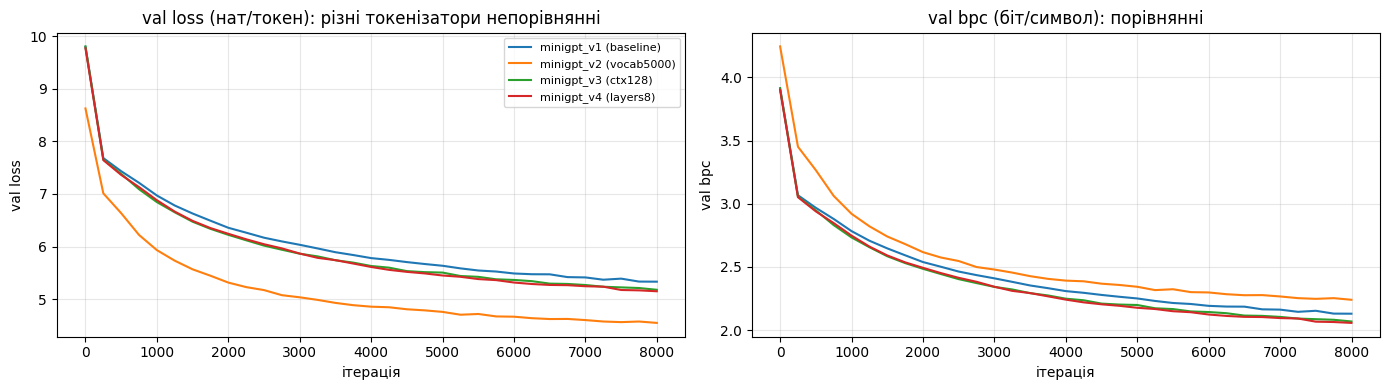

In [22]:
# 3.4. Таблиця результатів і крива навчання
rows = []
for vid, (label, change) in VARIANTS.items():
    r, c = runs[vid], variant_cfg[vid]
    rows.append({"id": vid, "варіант": label, "vocab": c["vocab"], "context": c["context_len"], "layers": c["n_layers"],
                 "params": r["n_params"], "best_iter": r["best_iter"], "best_val_loss": round(r["best_val"], 4),
                 "last_val_loss": round(r["last_val"], 4), "val_bpc": round(val_to_bpc(r["best_val"], c), 4),
                 "train_min": round(r["total_min"], 1)})
    results_rows.append({"part": "minigpt", "id": vid, "name": label, "task": "language-modeling",
                         "setting": f"vocab={c['vocab']}, ctx={c['context_len']}, layers={c['n_layers']}, heads={c['n_heads']}, embed={c['embed_dim']}, iters={c['max_iters']}",
                         "val_loss": round(r["best_val"], 4), "val_bpc": round(val_to_bpc(r["best_val"], c), 4),
                         "params_m": round(r["n_params"] / 1e6, 3), "time_min": round(r["total_min"], 1)})
minigpt_df = pd.DataFrame(rows).set_index("id")
display(minigpt_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for vid, (label, _) in VARIANTS.items():
    h, c = runs[vid]["hist"], variant_cfg[vid]
    axes[0].plot(h["iters"], h["val"], label=f"{vid} ({label})")
    axes[1].plot(h["iters"], [val_to_bpc(v, c) for v in h["val"]], label=f"{vid} ({label})")
axes[0].set_title("val loss (нат/токен): різні токенізатори непорівнянні"); axes[1].set_title("val bpc (біт/символ): порівнянні")
for ax in axes: ax.set_xlabel("ітерація"); ax.grid(alpha=0.3)
axes[0].set_ylabel("val loss"); axes[1].set_ylabel("val bpc"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Генерація (той самий промпт і seed для всіх)

In [23]:
# 3.5. Генерація на чекпоінті з найкращим val_loss: ОДИН промпт, ОДИН seed для всіх варіантів
GEN_PROMPT = "Місто Житомир розташоване на"

def generate_from_checkpoint(vid, prompt=GEN_PROMPT, max_new_tokens=60, temperature=0.8, top_k=40, seed=0):
    ckpt = torch.load(os.path.join(MODELS_DIR, f"{vid}.pt"), map_location=device)
    cfg = ckpt["config"]
    tok = Tokenizer.from_str(ckpt["tokenizer_json"])
    m = MiniGPT(tok.get_vocab_size(), cfg["embed_dim"], cfg["n_heads"], cfg["n_layers"], cfg["context_len"], cfg["dropout"]).to(device)
    m.load_state_dict(ckpt["state_dict"])
    ids = torch.tensor([tok.encode(prompt).ids], dtype=torch.long).to(device)
    torch.manual_seed(seed)
    return tok.decode(m.generate(ids, max_new_tokens, temperature=temperature, top_k=top_k)[0].tolist())

for vid, (label, _) in VARIANTS.items():
    r = runs[vid]
    print(f"=== {vid} ({label}) | best iter {r['best_iter']}, val_loss={r['best_val']:.3f}, bpc={val_to_bpc(r['best_val'], variant_cfg[vid]):.3f} ===")
    print(generate_from_checkpoint(vid))
    print()

=== minigpt_v1 (baseline) | best iter 7999, val_loss=5.334, bpc=2.130 ===
Місто Житомир розташоване на півночі в Азії, на півдні Індії на півдні  лежать невеликі незалежні герцогства, південь на півдні України. Вона має колонії в Північній Америці та на Цейлоні. Король Франції є Венеціанська республіка, а Король  Норвегії —  Фредерік V (до 1648). 

Україну розділено між Австрією в Америці та Московією.

=== minigpt_v2 (vocab5000) | best iter 7999, val_loss=4.551, bpc=2.240 ===
Місто Житомир розташоване на півночі в Індійському океанським та заході з Данилочини, південь Італії, на заході континенту належить до складу Воробрий, деякі області.

У Китаї,  править династія Мін.

Події 
 Імператор Священної Римської імперії захопили Альмані. В Японії триває

=== minigpt_v3 (ctx128) | best iter 7999, val_loss=5.180, bpc=2.068 ===
Місто Житомир розташоване на півночі в межах Придніпровщини. Адміністративний центр — місто Новенське, що на сході — близько 5000 км.

Історія 
У Європі межує на схо

### Висновки до розділу 3

**Таблиця варіантів** (3.4, `val_bpc` це біт на символ, тобто порівнянна між різними токенізаторами метрика):

| варіант | що змінено | `val_loss` | `val_bpc` | параметрів | час |
|---|---|---|---|---|---|
| `minigpt_v1` | базовий | 5.334 | 2.130 | 4.91 млн | 5.9 хв |
| `minigpt_v2` | словник 5000 | **4.551** | 2.240 | 2.09 млн | 3.1 хв |
| `minigpt_v3` | контекст 128 | 5.180 | 2.068 | 4.92 млн | 12.1 хв |
| `minigpt_v4` | 8 шарів | 5.152 | **2.057** | 5.70 млн | 7.8 хв |

**Який варіант кращий і чому `val_loss` обманює.** За сирим `val_loss` найкращий `minigpt_v2` (4.55), але це ілюзія: з меншим словником токени коротші (3.01 проти 3.75 символа на токен), тож ймовірність вгадати коротший токен вища, а loss на токен нижчий. За чесною метрикою `val_bpc` `minigpt_v2` навпаки **найгірший** (2.240, на 5% гірше за базовий). Найкращий за `val_bpc` `minigpt_v4` (8 шарів, 2.057), трохи позаду `minigpt_v3` (контекст 128, 2.068). Різниця між v3 і v4 (0.011 біт/символ) навряд чи значуща: це один seed на одній валідаційній вибірці, а розкид між seed я не вимірював, тому ці два варіанти не розділяю.

**Що дало найбільший ефект.** Відносно базового варіанта: глибина (+4 шари) дала −3.4% `val_bpc` за +32% часу й +16% параметрів; довший контекст −2.9% за +105% часу (з тією ж кількістю параметрів, але вдвічі більше токенів на батч і квадратична увага); менший словник +5.2% (гірше), але в 2.4 рази менше параметрів і вдвічі швидше (матриця embedding і `lm_head` при 16000 токенів становлять більшу частину параметрів). Найкращий виграш на одиницю витрат дала глибина, найдешевша втрата якості це менший словник.

**Головне спостереження: усі моделі недонавчені.** У всіх варіантів найкращий чекпоінт це остання ітерація, `val_loss` ще падає (у v1 ≈ 0.08 за останню 1000 ітерацій), тож більше ітерацій дало б більший ефект, ніж будь-яка зміна архітектури з таблиці (див. відповідь 8).

**Що видно в згенерованому тексті** (3.5, один промпт «Місто Житомир розташоване на», один seed, `temperature = 0.8`, `top_k = 40`). Усі чотири моделі навчились *форми* вікіпедійного тексту: українська морфологія в основному правильна, є розділи («Історія», «Події»), роки, назви держав і правителів. Але *зміст* вигаданий: жодна не знає Житомира, а тексти дрейфують до історії Європи («Король Франції…», «Священної Римської імперії», «династія Мін»), імовірно, тому що серед перших 12 000 статей корпусу багато загальних тем і сторінок про роки та століття (перші заголовки це «Географія», «Атом», «Мільярд», а модель постійно скочується до розділів «Події» та до дат; повний склад корпусу я не перевіряв). `minigpt_v3` найбільше нагадує статтю про населений пункт («Адміністративний центр — місто Новенське»), що збігається з тим, що довший контекст краще тримає жанр. У `minigpt_v2` найбільше «зламаних» слів («Воробрий», «Альмані»), у `minigpt_v4` помітні повтори («займає займає»). Втім один зразок на варіант це не вимірювання якості, і візуальна оцінка тут лише ілюструє різницю в `val_bpc`, а не доводить її.

**Обмеження.** Один seed на варіант; одна валідаційна вибірка; 8–10 млн токенів у train (для порівняння, для сучасних LLM це на порядки менше); модель на 2–6 млн параметрів. Тож абсолютні числа слабкі, і тільки відносні порівняння мають сенс.

#### Питання 10: частіша оцінка (`EVAL_INTERVAL`)

=== minigpt_v1 з EVAL_INTERVAL=50 ===
  [minigpt_v1_baseline_eval50] iter     0  train=9.793  val=9.795  (0.0 хв)
  [minigpt_v1_baseline_eval50] iter   200  train=7.714  val=7.714  (0.2 хв)
  [minigpt_v1_baseline_eval50] iter   400  train=7.521  val=7.544  (0.5 хв)
  [minigpt_v1_baseline_eval50] iter   600  train=7.315  val=7.375  (0.7 хв)
  [minigpt_v1_baseline_eval50] iter   800  train=7.087  val=7.167  (0.9 хв)
  [minigpt_v1_baseline_eval50] iter  1000  train=6.880  val=6.992  (1.1 хв)
  [minigpt_v1_baseline_eval50] iter  1200  train=6.688  val=6.808  (1.3 хв)
  [minigpt_v1_baseline_eval50] iter  1400  train=6.525  val=6.694  (1.5 хв)
  [minigpt_v1_baseline_eval50] iter  1600  train=6.356  val=6.552  (1.8 хв)
  [minigpt_v1_baseline_eval50] iter  1800  train=6.245  val=6.456  (2.0 хв)
  [minigpt_v1_baseline_eval50] iter  2000  train=6.160  val=6.377  (2.2 хв)
  [minigpt_v1_baseline_eval50] iter  2200  train=6.062  val=6.269  (2.5 хв)
  [minigpt_v1_baseline_eval50] iter  2400  train=5

,EVAL_INTERVAL,точок на кривій,"час на estimate_loss, с",частка від повного часу,"повний час, хв"
0,250,33,45.2,12.9%,5.9
1,50,161,222.7,42.2%,8.8


Один виклик estimate_loss ≈ 1.38 с => прогноз накладних витрат для EVAL_INTERVAL=10: ≈ 18.4 хв, для 1: ≈ 184 хв


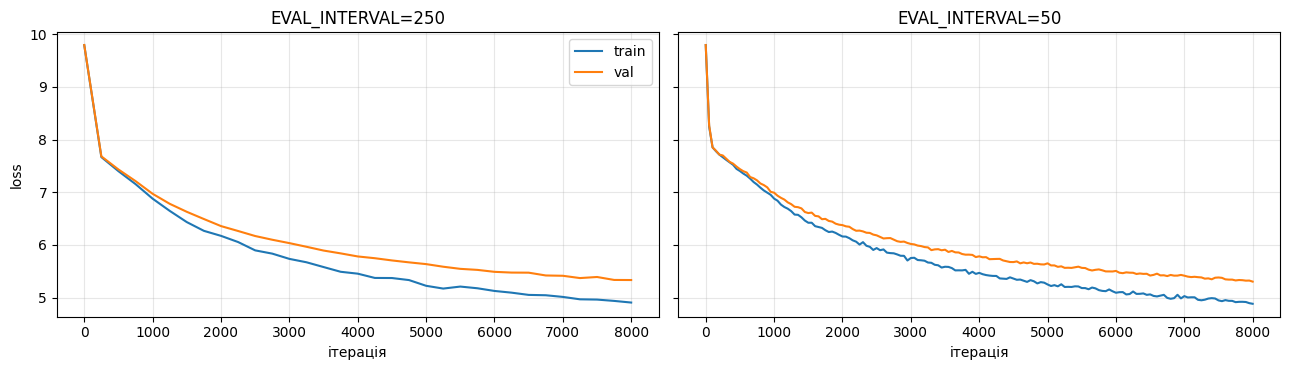

In [24]:
# 3.6. Питання 10: EVAL_INTERVAL 250 -> 50 (та сама базова конфігурація; лог у runs/, .pt не зберігаємо)
cfg_e50 = {**BASE_CFG, "eval_interval": max(2, BASE_CFG["eval_interval"] // 5)}
print(f"=== minigpt_v1 з EVAL_INTERVAL={cfg_e50['eval_interval']} ===")
res_e50 = train_variant("minigpt_v1_baseline_eval50", cfg_e50)
base = runs["minigpt_v1"]

per_eval = res_e50["eval_seconds"] / res_e50["n_evals"]
table = pd.DataFrame([
    {"EVAL_INTERVAL": BASE_CFG["eval_interval"], "точок на кривій": base["n_evals"], "час на estimate_loss, с": round(base["eval_seconds"], 1),
     "частка від повного часу": f"{base['eval_seconds'] / (base['total_min'] * 60):.1%}", "повний час, хв": round(base["total_min"], 1)},
    {"EVAL_INTERVAL": cfg_e50["eval_interval"], "точок на кривій": res_e50["n_evals"], "час на estimate_loss, с": round(res_e50["eval_seconds"], 1),
     "частка від повного часу": f"{res_e50['eval_seconds'] / (res_e50['total_min'] * 60):.1%}", "повний час, хв": round(res_e50["total_min"], 1)}])
display(table)
print(f"Один виклик estimate_loss ≈ {per_eval:.2f} с => прогноз накладних витрат для EVAL_INTERVAL=10: ≈ {per_eval * BASE_CFG['max_iters'] / 10 / 60:.1f} хв, для 1: ≈ {per_eval * BASE_CFG['max_iters'] / 60:.0f} хв")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (nm, rr) in zip(axes, [(f"EVAL_INTERVAL={BASE_CFG['eval_interval']}", base), (f"EVAL_INTERVAL={cfg_e50['eval_interval']}", res_e50)]):
    ax.plot(rr["hist"]["iters"], rr["hist"]["train"], label="train"); ax.plot(rr["hist"]["iters"], rr["hist"]["val"], label="val")
    ax.set_title(nm); ax.set_xlabel("ітерація"); ax.grid(alpha=0.3)
axes[0].set_ylabel("loss"); axes[0].legend(); plt.tight_layout(); plt.show()
del res_e50; cleanup()

In [25]:
# Зберігаємо все потрібне на диск і вивільняємо пам'ять перед розділом 4 (див. умову розділу 4)
print("Збережені чекпоінти:", sorted(os.listdir(MODELS_DIR)))
corpora_info = {V_: dict(n_tokens=c["n_tokens"]) for V_, c in corpora.items()}
for name in ["runs", "corpora", "tokenizers_cmp", "corpus_text", "wiki_df", "rows", "poems_all", "demo_data", "demo_train", "demo_val"]:
    if name in globals():
        del globals()[name]
cleanup()

Збережені чекпоінти: ['minigpt_v1.pt', 'minigpt_v2.pt', 'minigpt_v3.pt', 'minigpt_v4.pt']


---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [26]:
!pip install "transformers[sentencepiece]==5.18.0"

In [27]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [28]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [29]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to be a good manager in your own home.\n\nThis course will teach you the best approach to managing your finances and finances.'}, {'generated_text': "In this course, we will teach you how to use it and how to use it.\n\n\n\nHere's my main goal:\n• Use it to learn how to use it.\n• Give you a great lesson.\n• Use it to learn how to use it.\n• Teach you how to use it.\n• Teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you how to use it.\nThis course will teach you 

In [30]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [31]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [32]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

In [33]:
# Звільняємо пам'ять після прикладів 4.0 (кожен pipeline тримає окрему модель)
for name in ["classifier", "generator", "unmasker", "ner", "question_answerer"]:
    if name in globals():
        del globals()[name]
cleanup(hf_cache=SMOKE)

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [34]:
# 4.1. Спільні налаштування для прикладів з українськими текстами
from transformers import pipeline
DEV = 0 if torch.cuda.is_available() else -1      # 0 = перший GPU, -1 = CPU
set_seed()

In [35]:
# 4.1.1. Sentiment analysis (багатомовна XLM-R, навчена на твітах 8 мов; українська в тренуванні була)
sentiment_ua = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual", device=DEV)
reviews_ua = ["Ця навчальна платформа неймовірно зручна, я нарешті все зрозумів!",
              "Лекція була нудною, а демо-ноутбук постійно падав із помилкою.",
              "Нормально, нічого особливого."]
for r, o in zip(reviews_ua, sentiment_ua(reviews_ua)):
    print(f"{o['label']:9s} {o['score']:.2f}  | {r}")
del sentiment_ua; cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/982 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

positive  0.99  | Ця навчальна платформа неймовірно зручна, я нарешті все зрозумів!
negative  0.91  | Лекція була нудною, а демо-ноутбук постійно падав із помилкою.
positive  0.59  | Нормально, нічого особливого.


In [36]:
# 4.1.2. Zero-shot classification (mDeBERTa-v3, навчена на NLI-даних 100+ мов)
zs_ua = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", device=DEV)
news = ["Збірна України з футболу перемогла в класифікаційному матчі з рахунком 2:1.",
        "Національний банк підвищив облікову ставку для стримування інфляції.",
        "Науковці створили новий матеріал для акумуляторів, який заряджається за хвилини."]
for n in news:
    r = zs_ua(n, candidate_labels=["спорт", "економіка", "наука", "культура"], hypothesis_template="Це новина про {}.")
    print(f"{r['labels'][0]:10s} {r['scores'][0]:.2f}  | {n}")
del zs_ua; cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

спорт      0.97  | Збірна України з футболу перемогла в класифікаційному матчі з рахунком 2:1.
економіка  0.94  | Національний банк підвищив облікову ставку для стримування інфляції.
наука      0.84  | Науковці створили новий матеріал для акумуляторів, який заряджається за хвилини.


In [37]:
# 4.1.3. Text generation (GPT-2 124M, навчена на українському тексті: malteos/gpt2-uk)
gen_ua = pipeline("text-generation", model="malteos/gpt2-uk", device=DEV)
out = gen_ua("Одного ранку Житомир прокинувся від того, що", max_new_tokens=40, do_sample=True,
             temperature=0.8, top_p=0.9, num_return_sequences=2)
for o in out:
    print("-", o["generated_text"].replace("\n", " "))
del gen_ua; cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  511MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'max_new_tokens', 'num_return_sequences', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=40) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


- Одного ранку Житомир прокинувся від того, що його на вулиці обступили перехожі. Двері будинку були замкнені. В цей час до нього прибігла молода дівчина, яка вирішила допомогти йому і допомогти в скрутні хвилини. Після того
- Одного ранку Житомир прокинувся від того, що прокинувся і відчув, що в його серці, як у собаки, загорілася любов. І ось одного разу, злий чоловік пішов з дому. І ось, прокинувшись, він побачив,


In [38]:
# 4.1.4. Fill-mask (xlm-roberta-base: маска пишеться <mask>)
unmasker_ua = pipeline("fill-mask", model="xlm-roberta-base", device=DEV)
for s in ["Київ — столиця <mask>.", "Тарас Шевченко написав збірку «<mask>»."]:
    print(s)
    for o in unmasker_ua(s, top_k=3):
        print(f"   {o['token_str']:12s} {o['score']:.2f}")
del unmasker_ua; cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Київ — столиця <mask>.
   України      0.44
   .            0.09
   Україна      0.05
Тарас Шевченко написав збірку «<mask>».
   Шевченко     0.38
   Україна      0.24
   Майдан       0.03


In [39]:
# 4.1.5. NER (XLM-R, дотренована на українському корпусі lang-uk/ner-uk)
ner_ua = pipeline("ner", model="EvanD/xlm-roberta-base-ukrainian-ner-ukrner", aggregation_strategy="simple", device=DEV)
for s in ["Тарас Шевченко народився в селі Моринці на Черкащині, а працював у Києві.",
          "Житомирська політехніка співпрацює з компанією Easygenerator."]:
    print(s)
    for e in ner_ua(s):
        print(f"   {e['word']:22s} {e['entity_group']:5s} {float(e['score']):.2f}")
del ner_ua; cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Тарас Шевченко народився в селі Моринці на Черкащині, а працював у Києві.
   Тарас Шевченко         PER   0.85
   Моринці                LOC   0.99
   Черкащині              LOC   0.99
   Києві                  LOC   1.00
Житомирська політехніка співпрацює з компанією Easygenerator.
   техніка                ORG   0.57
   Easygenerator          ORG   0.98


In [40]:
# 4.1.6. Table question answering. Спершу: готовий TAPAS (навчений англійською) на українській таблиці
labs_ua = {"Лабораторна": ["Лінійні моделі", "Нейронні мережі", "Трансформери"],
           "Максимальний бал": ["10", "15", "20"],
           "Інструмент": ["PyTorch", "TensorBoard", "Hugging Face"]}
tapas = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq", device=DEV)
q_ua = ["Скільки балів дають за лабораторну про трансформери?", "Яка лабораторна найцінніша?"]
for q in q_ua:
    print("TAPAS (укр.):", q, "->", tapas(query=q, table=labs_ua)["answer"])
labs_en = {"Lab": ["Linear models", "Neural networks", "Transformers"], "Max score": ["10", "15", "20"]}
print("TAPAS (англ., для порівняння):", tapas(query="How many points is the Transformers lab worth?", table=labs_en)["answer"])
del tapas; cleanup(hf_cache=SMOKE)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

TAPAS (укр.): Скільки балів дають за лабораторну про трансформери? -> Трансформери
TAPAS (укр.): Яка лабораторна найцінніша? -> Лінійні моделі
TAPAS (англ., для порівняння): AVERAGE > 20


In [41]:
# 4.1.6 (продовження). Українськомовного TAPAS немає, тож таблицю «читає» багатомовна інструктивна LLM
from transformers import AutoModelForCausalLM, AutoTokenizer
TABLE_LLM = "Qwen/Qwen2.5-0.5B-Instruct" if SMOKE else "Qwen/Qwen2.5-1.5B-Instruct"
tl_tok = AutoTokenizer.from_pretrained(TABLE_LLM)
tl_model = AutoModelForCausalLM.from_pretrained(TABLE_LLM, torch_dtype="auto").to(device).eval()

def table_to_markdown(table):
    cols = list(table); n = len(next(iter(table.values())))
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(table[c][i] for c in cols) + " |" for i in range(n)]
    return "\n".join(lines)

def ask_table(question, table):
    msgs = [{"role": "system", "content": "Відповідай коротко українською, використовуючи лише дані таблиці."},
            {"role": "user", "content": f"Таблиця:\n{table_to_markdown(table)}\n\nПитання: {question}"}]
    text = tl_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tl_tok([text], return_tensors="pt").to(device)
    out = tl_model.generate(**inputs, max_new_tokens=40, do_sample=False)
    return tl_tok.decode(out[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True).strip()

for q in q_ua:
    print("LLM:", q, "->", ask_table(q, labs_ua))
del tl_model, tl_tok; cleanup(hf_cache=SMOKE)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM: Скільки балів дають за лабораторну про трансформери? -> За лабораторну про трансформери даються 20 балів.
LLM: Яка лабораторна найцінніша? -> Найцінніша лабораторна - "Нейронні мережі" з максимальним балом 15 та інструментом Tensor


**Коментар до 4.1** (шість задач, українські приклади):

- **Sentiment, zero-shot, NER** працюють добре, коли взято багатомовну модель. XLM-R правильно визначила «зручна платформа» як positive (0.99) і «нудна лекція» як negative (0.91), але для нейтрального «Нормально, нічого особливого.» дала positive 0.59: нейтральність вона відрізняє слабко. mDeBERTa (zero-shot) без помилок розподілила три новини за темами (спорт 0.97, економіка 0.94, наука 0.84). NER-модель, дотренована на українському корпусі, знайшла `PER` («Тарас Шевченко», 0.85) і всі `LOC` (Моринці, Черкащині, Києві, 0.99–1.00) та `ORG` Easygenerator (0.98), але в «Житомирська політехніка» виділила лише слово «техніка» (0.57), тобто межі організації визначила неправильно.
- **Fill-mask** знає найочевидніше («Київ — столиця <mask>» → «України», 0.44), але не знає менш очевидного: на «Тарас Шевченко написав збірку «<mask>»» перші відповіді «Шевченко» (0.38) і «Україна» (0.24), а не «Кобзар». Базова XLM-R слабка у фактах.
- **Text generation** (`malteos/gpt2-uk`) генерує зв'язну українську, але з логічними збоями («Житомир прокинувся… його на вулиці обступили перехожі»: місто стало людиною).
- **Table QA:** відмінності найпоказовіші. Англомовний TAPAS на українській таблиці відповідає хибно (повертає назву лабораторної замість балів і «Лінійні моделі» на питання про найцінніше), бо його токенізатор і навчання англійські. Для порівняння, на англійському запитанні дає `AVERAGE > 20`, тобто агрегат над коміркою зі значенням 20 (правильно за змістом, але у вигляді команди). Українськомовного TAPAS немає, тож я «читав» таблицю багатомовною інструктивною LLM (`Qwen2.5-1.5B-Instruct`): на питання «Скільки балів за лабораторну про трансформери?» вона відповіла правильно (20), а на «Яка лабораторна найцінніша?» помилилась: назвала «Нейронні мережі (15 балів)» замість «Трансформери (20)». Тобто порівняння («найбільше») модель такого розміру ще не тримає.

Загальний висновок: українська працює там, де є багатомовна модель чи модель, дотренована на українських даних; англомоделі «з коробки» (TAPAS) нічого не дають.

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [42]:
# 5.1. Задача: sentiment-analysis. Метрики: accuracy та F1 (клас positive = 1). 20 власних речень
SENT_DATA = [
    ("Дуже смачна піца, обслуговування швидке, обов'язково повернемося!", "positive"),
    ("Не можу сказати, що фільм поганий: він мене приємно здивував.", "positive"),          # заперечення, але позитив
    ("Смартфон працює швидко, а акумулятора вистачає на два дні.", "positive"),
    ("Чудовий готель: чисто, привітний персонал і розкішний краєвид з вікна.", "positive"),
    ("Я в захваті від цієї книжки, не міг відірватися до самого ранку.", "positive"),
    ("Кур'єр приїхав раніше, ніж обіцяли, і ще й усміхався.", "positive"),
    ("Концерт був просто казковий, мурашки по шкірі від першої до останньої пісні.", "positive"),
    ("Нарешті знайшов зручні кросівки, ноги зовсім не втомлюються.", "positive"),
    ("Підтримка вирішила мою проблему за п'ять хвилин, дякую за професіоналізм!", "positive"),
    ("Прекрасна погода, море тепле, відпустка вдалася на всі сто.", "positive"),
    ("Жахливий сервіс: чекали на замовлення дві години, а їжа була холодна.", "negative"),
    ("Дякую за чудовий сервіс: пів години слухав музику на лінії очікування.", "negative"),  # іронія
    ("Телефон зламався через тиждень, гроші викинуті на вітер.", "negative"),
    ("У номері брудно, відчувався запах цвілі, ніколи більше сюди не поїду.", "negative"),
    ("Книжка розчарувала: нудний сюжет і картонні персонажі.", "negative"),
    ("Посилку загубили, а на мої листи ніхто не відповідає.", "negative"),
    ("Концерт скасували в останній момент, а гроші за квитки досі не повернули.", "negative"),
    ("Взуття розвалилося після першого ж дощу, огидна якість.", "negative"),
    ("Менеджер нахамив мені по телефону й просто поклав слухавку.", "negative"),
    ("Усю відпустку лив дощ, а готель виявився зовсім не таким, як на фото.", "negative"),
]
sent_texts = [t for t, _ in SENT_DATA]
sent_gold = [1 if l == "positive" else 0 for _, l in SENT_DATA]
print("Прикладів:", len(SENT_DATA), "| positive:", sum(sent_gold), "| negative:", len(sent_gold) - sum(sent_gold))

Прикладів: 20 | positive: 10 | negative: 10


### 5.2. Порівняння моделей

In [43]:
# 5.2. Порівняння моделей на однакових вхідних прикладах: метрики, швидкість, розмір
import evaluate
from transformers import pipeline
acc_metric, f1_metric = evaluate.load("accuracy"), evaluate.load("f1")
DEV = 0 if torch.cuda.is_available() else -1

CANDIDATES = {
    "distilbert-multilingual": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "xlm-roberta (twitter)":   "cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual",
    "bert-multilingual (stars)": "nlptown/bert-base-multilingual-uncased-sentiment",
}

def pos_prob(model_id, outs):
    # P(positive) відносно P(negative): нейтральний клас (де він є) ігноруємо, бо наша розмітка бінарна
    sc = {o["label"].lower(): o["score"] for o in outs}
    if "nlptown" in model_id:                       # 1-5 зірок: 4-5 = позитив, 1-2 = негатив
        pos, neg = sc["4 stars"] + sc["5 stars"], sc["1 star"] + sc["2 stars"]
    else:
        pos, neg = sc["positive"], sc["negative"]
    return pos / (pos + neg)

def score_probs(probs, threshold=0.5):
    pred = [int(p >= threshold) for p in probs]
    return (acc_metric.compute(predictions=pred, references=sent_gold)["accuracy"],
            f1_metric.compute(predictions=pred, references=sent_gold)["f1"],
            [i + 1 for i, (a, b) in enumerate(zip(pred, sent_gold)) if a != b])

model_probs, rows = {}, []
for name, mid in CANDIDATES.items():
    pipe = pipeline("sentiment-analysis", model=mid, top_k=None, device=DEV)
    n_params = sum(p.numel() for p in pipe.model.parameters()) / 1e6
    pipe(sent_texts[:2])                                                        # прогрів (ініціалізація CUDA/кешів)
    times = []
    for _ in range(3):
        t0 = time.time(); outs = pipe(sent_texts); times.append((time.time() - t0) / len(sent_texts))
    probs = [pos_prob(mid, o) for o in outs]
    model_probs[name] = probs
    acc, f1, wrong = score_probs(probs)
    rows.append({"модель": name, "параметрів, млн": round(n_params), "accuracy": round(acc, 2), "F1": round(f1, 2),
                 "мс на речення": round(1000 * float(np.mean(times)), 1), "пристрій": "GPU" if DEV >= 0 else "CPU",
                 "помилки (№ речень)": wrong})
    results_rows.append({"part": "model_comparison", "id": mid, "name": name, "task": "sentiment-analysis", "setting": "default (поріг 0.5)",
                         "accuracy": round(acc, 4), "f1": round(f1, 4), "params_m": round(n_params, 1),
                         "ms_per_sentence": round(1000 * float(np.mean(times)), 1), "device": "GPU" if DEV >= 0 else "CPU"})
    del pipe; cleanup(hf_cache=SMOKE)
compare_df = pd.DataFrame(rows).set_index("модель")
display(compare_df)
BEST_NAME = compare_df["F1"].idxmax()
BEST_SENT_ID = CANDIDATES[BEST_NAME]
print("Найкраща за F1:", BEST_NAME, "->", BEST_SENT_ID)

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,"параметрів, млн",accuracy,F1,мс на речення,пристрій,помилки (№ речень)
модель,,,,,,
distilbert-multilingual,135,0.60,0.33,6.1,GPU,"[1, 2, 5, 6, 7, 8, 9, 10]"
xlm-roberta (twitter),278,0.90,0.91,11.5,GPU,"[12, 18]"
bert-multilingual (stars),167,0.75,0.71,11.0,GPU,"[1, 5, 7, 9, 12]"


Найкраща за F1: xlm-roberta (twitter) -> cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual


### 5.3. Налаштування

In [44]:
# 5.3. Налаштування найкращої моделі: по ОДНІЙ зміні за раз відносно «default»
def probs_for(model_id, inputs):
    pipe = pipeline("sentiment-analysis", model=model_id, top_k=None, device=DEV)
    out = [pos_prob(model_id, o) for o in pipe(inputs)]
    del pipe; cleanup(hf_cache=SMOKE); return out

strip_punct = lambda t: re.sub(r"[^\w\s]", "", t)
base_probs = model_probs[BEST_NAME]
variants = {
    "default (поріг 0.5)":        base_probs,
    "поріг P(pos) = 0.3":         ("thr", 0.3),
    "поріг P(pos) = 0.7":         ("thr", 0.7),
    "вхід: нижній регістр":       probs_for(BEST_SENT_ID, [t.lower() for t in sent_texts]),
    "вхід: без пунктуації":       probs_for(BEST_SENT_ID, [strip_punct(t) for t in sent_texts]),
    "вхід: префікс «Відгук: »":   probs_for(BEST_SENT_ID, ["Відгук: " + t for t in sent_texts]),
}
rows = []
for setting, spec in variants.items():
    probs, thr = (base_probs, spec[1]) if isinstance(spec, tuple) else (spec, 0.5)
    acc, f1, wrong = score_probs(probs, thr)
    rows.append({"модель": BEST_NAME, "налаштування": setting, "accuracy": round(acc, 2), "F1": round(f1, 2), "помилки (№)": wrong})
    results_rows.append({"part": "settings_experiment", "id": BEST_SENT_ID, "name": BEST_NAME, "task": "sentiment-analysis",
                         "setting": setting, "accuracy": round(acc, 4), "f1": round(f1, 4)})
settings_df = pd.DataFrame(rows).set_index("налаштування")
display(settings_df)

# Для контексту: той самий поріг/препроцесинг на ВСІХ моделях (модель × налаштування -> F1)
grid = {}
for name, probs in model_probs.items():
    grid[name] = {"default": score_probs(probs)[1], "поріг 0.3": score_probs(probs, 0.3)[1], "поріг 0.7": score_probs(probs, 0.7)[1]}
display(pd.DataFrame(grid).round(2).T)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,модель,accuracy,F1,помилки (№)
налаштування,,,,
default (поріг 0.5),xlm-roberta (twitter),0.90,0.91,"[12, 18]"
поріг P(pos) = 0.3,xlm-roberta (twitter),0.90,0.91,"[12, 18]"
поріг P(pos) = 0.7,xlm-roberta (twitter),0.90,0.91,"[12, 18]"
вхід: нижній регістр,xlm-roberta (twitter),0.90,0.91,"[12, 18]"
вхід: без пунктуації,xlm-roberta (twitter),0.85,0.86,"[7, 12, 18]"
вхід: префікс «Відгук: »,xlm-roberta (twitter),0.90,0.91,"[12, 18]"


,default,поріг 0.3,поріг 0.7
distilbert-multilingual,0.33,0.70,0.18
xlm-roberta (twitter),0.91,0.91,0.91
bert-multilingual (stars),0.71,0.74,0.75


### Висновки до розділу 5

**Порівняння моделей** (sentiment-analysis, 20 власних речень, GPU T4):

| модель | параметрів | accuracy | F1 | мс на речення |
|---|---|---|---|---|
| `distilbert-multilingual` | 135 млн | 0.60 | 0.33 | 6.1 |
| `xlm-roberta (twitter)` | 278 млн | **0.90** | **0.91** | 11.5 |
| `bert-multilingual (stars)` | 167 млн | 0.75 | 0.71 | 11.0 |

**Висновок.** Найкраща модель за F1 `xlm-roberta (twitter)`: на 6 речень (з 20) краща за `distilbert`, а ціна лише ≈ 2× за часом на речення (11.5 проти 6.1 мс) при ≈ 2× більшій кількості параметрів (значну частину яких, ймовірно, складає великий багатомовний словник, а не «розумність»). `distilbert-multilingual` майже все називає негативним (помилки в №1, 2, 5–10, тобто майже у всіх позитивних): її F1 для класу positive лише 0.33, хоча формально accuracy 0.60. `bert-multilingual (stars)` пропускає позитивні відгуки (№1, 5, 7, 9) і не дотягує до XLM-R. **Речення №12** («Дякую за чудовий сервіс: пів години слухав музику на лінії очікування», іронія) помилково класифікували дві з трьох моделей (`xlm-roberta` і `bert-multilingual`): слова «чудовий» і «дякую» переважують. `distilbert` «вгадала» його лише тому, що майже все називає негативним. Найпростіше заперечення (№2, «Не можу сказати, що фільм поганий…») не впоралась лише `distilbert`. Дивна помилка XLM-R це №18 («Взуття розвалилося… огидна якість»), чисто негативне речення, і пояснення в мене немає.

**Налаштування `xlm-roberta`** (по одній зміні за раз):

- **Поріг 0.3 і 0.7:** без змін (accuracy 0.90, F1 0.91). Судячи з того, що жодне речення не змінило мітку, модель дуже впевнена (ймовірності далеко від порога), тож поріг її не зачіпає. А от для інших моделей поріг важливий: F1 `distilbert` зростає з 0.33 до 0.70 при порозі 0.3 (модель заниженно оцінює P(positive), і зсув порогу частково це виправляє), але падає до 0.18 при 0.7; у `bert-multilingual` 0.71 → 0.74 (поріг 0.3) і 0.75 (поріг 0.7).
- **Нижній регістр і префікс «Відгук: »:** без змін.
- **Без пунктуації:** гірше (accuracy 0.90 → 0.85, F1 0.91 → 0.86): речення №7 («Концерт був просто казковий, мурашки по шкірі…») стало помилковим. Модель частково спирається на пунктуацію, тож «очищати» текст від розділових знаків не варто.

**Обмеження.** Двадцять речень це дуже мало: одне речення це 5 п.п. accuracy, тож різниця між 0.90 і 0.85 це одна відповідь. Переконливою є лише різниця між XLM-R та `distilbert`. Класи збалансовані (10/10), але приклади написані мною, мають єдиний регістр і домени «відгук/сервіс», а не твіти, на яких навчена XLM-R. Нейтральні тексти не перевірялись.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [45]:
# 6. Gradio-застосунок «Радар відгуків»: по реченнях показує тональність і тему, а підсумок: які теми «болять»
import gradio as gr

APP_SENT_ID = "lxyuan/distilbert-base-multilingual-cased-sentiments-student" if SMOKE else BEST_SENT_ID
sent_app = pipeline("sentiment-analysis", model=APP_SENT_ID, top_k=None, device=DEV)
zs_app = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", device=DEV)

def split_sentences(text):
    parts = re.split(r"(?<=[.!?…])\s+|\n+", text.strip())
    return [p.strip() for p in parts if len(p.strip()) > 3]

def analyze(text, topics_csv):
    sents = split_sentences(text)
    topics = [t.strip() for t in topics_csv.split(",") if t.strip()]
    if not sents or len(topics) < 2:
        return "<i>Введіть текст (кілька речень) і щонайменше дві теми через кому.</i>", pd.DataFrame(), None
    pol = [2 * pos_prob(APP_SENT_ID, o) - 1 for o in sent_app(sents)]                  # від -1 (негатив) до +1 (позитив)
    zs = zs_app(sents, candidate_labels=topics, hypothesis_template="Це речення про {}.")
    zs = zs if isinstance(zs, list) else [zs]
    top = [z["labels"][0] for z in zs]
    html = ["<div style='line-height:2.1;font-size:15px'>"]
    for s, p, t in zip(sents, pol, top):
        color = f"rgba(46,160,67,{min(abs(p), 1) * 0.55 + 0.08})" if p >= 0 else f"rgba(218,54,51,{min(abs(p), 1) * 0.55 + 0.08})"
        html.append(f"<span style='background:{color};padding:3px 6px;border-radius:5px;margin-right:4px'>{s}"
                    f" <b style='font-size:11px;opacity:.75'>[{t} · {p:+.2f}]</b></span>")
    html.append("</div>")
    df = pd.DataFrame({"тема": top, "тональність": pol})
    summary = (df.groupby("тема").agg(речень=("тональність", "size"), середня_тональність=("тональність", "mean"),
                                      частка_негативних=("тональність", lambda x: float((x < 0).mean()))).round(2)
                 .sort_values("середня_тональність").reset_index())
    fig, ax = plt.subplots(figsize=(6, 0.55 * len(summary) + 1.2))
    ax.barh(summary["тема"], summary["середня_тональність"], color=["#da3633" if v < 0 else "#2ea043" for v in summary["середня_тональність"]])
    ax.axvline(0, color="gray", lw=0.8); ax.set_xlim(-1, 1); ax.set_xlabel("середня тональність (−1 … +1)")
    ax.set_title("Які теми викликають негатив"); plt.tight_layout(); plt.close(fig)
    return "".join(html), summary, fig

EXAMPLE = ("Замовлення доставили вчасно, кур'єр був ввічливий. Але товар виявився гіршим за фото, пластик тонкий і тріскається. "
           "Ціна завищена порівняно з конкурентами. Підтримка відповіла за пів години і швидко оформила повернення, дякую! "
           "Сайт незручний: оплата зависала двічі. Упаковка гарна, подарунок отримав задоволення.")
EXAMPLE_TOPICS = "доставка, якість товару, ціна, підтримка, сайт і оплата, упаковка"

# Перевіряємо логіку без UI
_h, _s, _f = analyze(EXAMPLE, EXAMPLE_TOPICS)
display(_s)

with gr.Blocks(title="Радар відгуків") as demo:
    gr.Markdown("## 📡 Радар відгуків\nВставте відгуки українською. Кожне речення отримує **тональність** (XLM-R/mBERT) і **тему** (zero-shot mDeBERTa) за вашим списком тем. Нижче видно, які теми «болять» найбільше.")
    with gr.Row():
        with gr.Column():
            txt = gr.Textbox(lines=8, label="Відгуки", value=EXAMPLE)
            tpc = gr.Textbox(label="Теми через кому", value=EXAMPLE_TOPICS)
            btn = gr.Button("Проаналізувати", variant="primary")
        with gr.Column():
            out_html = gr.HTML(label="Речення")
    with gr.Row():
        out_tbl = gr.Dataframe(label="Підсумок за темами")
        out_fig = gr.Plot(label="Тональність за темами")
    btn.click(analyze, inputs=[txt, tpc], outputs=[out_html, out_tbl, out_fig])

_, local_url, _ = demo.launch(share=IN_COLAB, prevent_thread_lock=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

,тема,речень,середня_тональність,частка_негативних
0,сайт і оплата,1,-0.98,1.0
1,якість товару,1,-0.97,1.0
2,ціна,1,-0.81,1.0
3,доставка,1,0.96,0.0
4,упаковка,1,0.99,0.0
5,підтримка,1,0.99,0.0


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cdfcb948030263ef54.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [46]:
# Наскрізна перевірка: викликаємо запущений застосунок через його API
try:
    from gradio_client import Client
    api = Client(local_url, verbose=False)
    html_out, tbl_out, _plot = api.predict(EXAMPLE, EXAMPLE_TOPICS, api_name="/analyze")
    print("Gradio API відповів: ОК | довжина HTML:", len(html_out))
except Exception as e:
    print("Перевірку через API пропущено:", e)

Gradio API відповів: ОК | довжина HTML: 1438


**Що це і навіщо.** «Радар відгуків» призначений для людини, яка отримала купу текстових відгуків (магазин, курс, сервіс) і хоче швидко зрозуміти, *що саме* у них не так, а не лише «скільки позитиву/негативу». Кожне речення проходить через дві готові моделі: тональність (з розділів 4–5) і тему (zero-shot, теми задає користувач). Підсумок показує середню тональність за темами, тож одразу видно, наприклад, що «доставка» хвалиться, а «сайт і оплата» дратує. Застосунок запускається у клітинці вище (у Colab з публічним посиланням).

### Збереження результатів

In [47]:
# Фінал: results.csv, архів артефактів
cols = ["part", "id", "name", "task", "setting", "val_loss", "val_bpc", "accuracy", "f1", "params_m", "ms_per_sentence", "device", "time_min"]
results_df = pd.DataFrame(results_rows).reindex(columns=cols)
results_df.to_csv("results.csv", index=False)
display(results_df)

assert all(os.path.exists(os.path.join(MODELS_DIR, f"minigpt_v{i}.pt")) for i in range(1, 5)), "відсутні чекпоінти mini-GPT"
assert os.path.isdir(RUNS_DIR) and len(os.listdir(RUNS_DIR)) >= 4, "відсутні логи TensorBoard"

ARCHIVE = "lab3_artifacts.zip"
with zipfile.ZipFile(ARCHIVE, "w", zipfile.ZIP_DEFLATED) as z:
    z.write("results.csv")
    for folder in (MODELS_DIR, RUNS_DIR):
        for root, _, files in os.walk(folder):
            for f in files:
                z.write(os.path.join(root, f))
print("Архів:", ARCHIVE, f"({os.path.getsize(ARCHIVE) / 1e6:.1f} МБ)")
if IN_COLAB:
    from google.colab import files
    files.download(ARCHIVE)             # завантажити на комп'ютер

,part,id,name,task,setting,val_loss,val_bpc,accuracy,f1,params_m,ms_per_sentence,device,time_min
0,minigpt,minigpt_v1,baseline,language-modeling,"vocab=16000, ctx=64, layers=4, heads=4, embed=...",5.3341,2.1298,NaN,NaN,4.912,NaN,NaN,5.9
1,minigpt,minigpt_v2,vocab5000,language-modeling,"vocab=5000, ctx=64, layers=4, heads=4, embed=1...",4.5512,2.2399,NaN,NaN,2.085,NaN,NaN,3.1
2,minigpt,minigpt_v3,ctx128,language-modeling,"vocab=16000, ctx=128, layers=4, heads=4, embed...",5.1800,2.0682,NaN,NaN,4.920,NaN,NaN,12.1
3,minigpt,minigpt_v4,layers8,language-modeling,"vocab=16000, ctx=64, layers=8, heads=4, embed=...",5.1519,2.0570,NaN,NaN,5.704,NaN,NaN,7.8
4,model_comparison,lxyuan/distilbert-base-multilingual-cased-sent...,distilbert-multilingual,sentiment-analysis,default (поріг 0.5),NaN,NaN,0.60,0.3333,135.300,6.1,GPU,NaN
5,model_comparison,cardiffnlp/twitter-xlm-roberta-base-sentiment-...,xlm-roberta (twitter),sentiment-analysis,default (поріг 0.5),NaN,NaN,0.90,0.9091,278.000,11.5,GPU,NaN
6,model_comparison,nlptown/bert-base-multilingual-uncased-sentiment,bert-multilingual (stars),sentiment-analysis,default (поріг 0.5),NaN,NaN,0.75,0.7059,167.400,11.0,GPU,NaN
7,settings_experiment,cardiffnlp/twitter-xlm-roberta-base-sentiment-...,xlm-roberta (twitter),sentiment-analysis,default (поріг 0.5),NaN,NaN,0.90,0.9091,NaN,NaN,NaN,NaN
8,settings_experiment,cardiffnlp/twitter-xlm-roberta-base-sentiment-...,xlm-roberta (twitter),sentiment-analysis,поріг P(pos) = 0.3,NaN,NaN,0.90,0.9091,NaN,NaN,NaN,NaN
9,settings_experiment,cardiffnlp/twitter-xlm-roberta-base-sentiment-...,xlm-roberta (twitter),sentiment-analysis,поріг P(pos) = 0.7,NaN,NaN,0.90,0.9091,NaN,NaN,NaN,NaN


Архів: lab3_artifacts.zip (66.1 МБ)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```